# Deep learning on weekly M5: which training settings matter, and where it beats LightGBM

This notebook reads finished runs from `results/` (it trains nothing) and answers two questions about N-HiTS in stock
NeuralForecast, tested on all 30,490 weekly M5 item-store series:

1. Which training settings matter? (sections 3 and 4)
2. Where can deep learning beat a LightGBM baseline? (sections 5 and 6)

Every comparison shows two numbers for both forecasts. **WMAPE** is the sum of absolute errors divided by the sum of actual
sales (lower is better). **|bias|** is how far total volume is off: |total forecast / total actual − 1|. Every number in
the text is computed from the results. Every example series is picked by a rule written in code, and the text says how
typical it is.

Sections: 1 the problem · 2 the recipe · 3 one setting at a time · 4 clipping under stress · 5 deep learning vs LightGBM ·
6 where to use deep learning.

In [1]:
import sys, os, json
try: import m5knobs  # noqa: F401  (installed with pip install -e .)
except ImportError: sys.path.insert(0, os.path.abspath(".."))  # run from notebooks/
import pandas as pd
from IPython.display import Image, Markdown, display
from m5knobs import data, examples, experiments, paths, report, results, segments, story
from m5knobs.figures import architectures, cards, compare, early_stopping, stress, segments as seg_fig
from m5knobs.figures.style import join_words as style_join, label_text
results.check_available()  # stops with instructions if results/ is missing
R = paths.RESULTS

In [2]:
def show(files):  # a figure function returns [png, svg], or [] when a run is missing
    if files:
        display(Image(files[0], width=820))

def section(arm_wrong, arm_right, rule, labels, title, name):
    t = examples.pair_table(R, arm_wrong, arm_right)  # the two runs, series by series
    pick = rule(t)                                     # the example series, chosen by the rule
    show(compare.draw(R, arm_wrong, arm_right, pick, labels, title, name))
    return t, pick

## 1. The problem

M5 is Walmart's public unit sales per item and store in three US states. Here it is summed to weeks ending Saturday, one
series per item-store pair, each starting at its first sale. Every model forecasts 13 weeks ahead from 3 origins, and at
each origin it sees only the history up to that date. Most item-store weeks sell a few units and many sell none: this is
intermittent demand.

In [3]:
hist, act = results.history(R), results.actuals(R)
year = hist[hist.ds > hist.ds.max() - pd.Timedelta(weeks=52)]  # the year before the first origin
zeros = year.y.eq(0).groupby(year.unique_id).mean()
origins = ", ".join(f"{pd.Timestamp(c):%Y-%m-%d}" for c in sorted(act.cutoff.unique()))
display(Markdown(
    f"{act.unique_id.nunique():,} series. In the year before the first origin, {year.y.eq(0).mean():.0%} of series-weeks "
    f"sold nothing; the median series had {zeros.median():.0%} zero weeks, and {zeros.gt(0.5).mean():.0%} of series had more "
    f"than half. Forecast: `h={data.H}` weeks, `freq='{data.FREQ}'`, origins {origins}; {act.y.sum():,.0f} units are scored "
    f"over {act.ds.nunique()} weeks. The data ends partway through its last week, so that partial week is not scored."))
no_hist = act.unique_id.nunique() - hist.unique_id.nunique()
display(Markdown(f"{no_hist:,} series first sold after the first origin, so they have no history there and get no neural "
                 "forecast before their first sale. They count in every WMAPE and |bias| (forecast = 0), but the "
                 "series-by-series counts below cover only the series both compared runs forecast."))

30,490 series. In the year before the first origin, 24% of series-weeks sold nothing; the median series had 17% zero weeks, and 15% of series had more than half. Forecast: `h=13` weeks, `freq='W-SAT'`, origins 2015-09-26, 2015-12-26, 2016-03-26; 10,796,897 units are scored over 38 weeks. The data ends partway through its last week, so that partial week is not scored.

82 series first sold after the first origin, so they have no history there and get no neural forecast before their first sale. They count in every WMAPE and |bias| (forecast = 0), but the series-by-series counts below cover only the series both compared runs forecast.

### How results are judged

- **WMAPE** over all series, weeks and origins. Big sellers weigh more than slow ones.
- **Bias** = total forecast / total actual − 1. Negative means the model under-forecast total volume; **|bias|** is its size.
- **One seed per run.** The noise bar, ±0.2 WMAPE and ±1pt |bias|, comes from the author's earlier 3-seed runs of the same
  model family on M5. Those runs are not in this repo, so treat the bar as approximate. Smaller gaps are ties.
- **The verdict rule** for a pair of runs (one setting wrong, one right) compares four measures series by series: fit to the
  training history, week-to-week tracking, how much the forecast moves, and |bias|. Each one is tested with a paired bootstrap
  over series (p < 0.05). The verdict is **underfit** if fit, tracking or movement got worse and the WMAPE gap is beyond the
  noise bar. It is **biased** if |bias| got worse by more than its noise bar, **both** if both hold, and otherwise **no clear
  effect on M5**. Two rules were set after seeing results: this noise floor, and the stress test's divergence rule
  (section 4).
- **Example series** are picked by a rule tied to the mechanism the section claims, mostly among series that sell at least
  the median volume. They are the clearest cases, not the average. The all-series panel under each example shows the
  average effect, and the text gives how many series behave the same way.
- **History windows:** per-series groupings used for examples (intermittent, mostly-zero, stock-outs) use the 60 weeks of
  history up to the first origin; the segment charts in section 5 use the last 52 of those weeks.

## 2. The recipe

The recipe is N-HiTS with these settings, built by `m5knobs.model.Knobs` from stock NeuralForecast arguments. Each
comparison below changes one of them. The loss is Tweedie, which allows exact zeros and a long right tail. Each input
window is scaled with RevIN, and the input window is one year long. Training uses NAdam with a one-cycle learning rate and
early stopping, restores the best weights at the end, and clips gradients with AutoClip. A short-history filter keeps
training windows that are mostly padding out of training.

In [4]:
import inspect
from m5knobs import model
r = {**{k: p.default for k, p in inspect.signature(model.Knobs).parameters.items()}, **data.RECIPE}
r["min_steps"] = int(0.3 * r["max_steps"])  # what Knobs uses when min_steps=None
skip = {"arch", "h", "seed", "accelerator", "freq", "huber_delta"}  # set per run, or only used by the Huber runs
display(pd.DataFrame({"recipe value": {k: str(v) for k, v in r.items() if k not in skip}}))

,recipe value
input_size,52
loss,tweedie
clip_percentile,10.0
restore_best,True
lr_max,0.001
max_steps,5000
val_check_steps,50
early_stop_patience_steps,20
min_steps,1500
scaler_type,revin


In [5]:
display(Markdown(f'''```python
NHITS(h={data.H}, input_size={r['input_size']}, scaler_type="{r['scaler_type']}",
      loss=make_loss("tweedie", tweedie_rho={r['tweedie_rho']}),  # m5knobs.model: stock Tweedie + zero-window guard
      batch_size={r['batch_size']}, windows_batch_size={r['windows_batch_size']}, start_padding_enabled=True, drop_last_loader=True,
      training_data_availability_threshold={list(r['availability_threshold'])},
      max_steps={r['max_steps']}, min_steps={r['min_steps']}, val_check_steps={r['val_check_steps']},
      early_stop_patience_steps={r['early_stop_patience_steps']}, optimizer=torch.optim.NAdam,
      lr_scheduler=OneCycleLR, lr_scheduler_kwargs=dict(max_lr={r['lr_max']}, ...),
      callbacks=[AutoClip({r['clip_percentile']}), BestWeights()])  # then nf.fit(df, val_size={r['val_size']})
```'''))

```python
NHITS(h=13, input_size=52, scaler_type="revin",
      loss=make_loss("tweedie", tweedie_rho=1.5),  # m5knobs.model: stock Tweedie + zero-window guard
      batch_size=128, windows_batch_size=1024, start_padding_enabled=True, drop_last_loader=True,
      training_data_availability_threshold=[0.05, 0.0],
      max_steps=5000, min_steps=1500, val_check_steps=50,
      early_stop_patience_steps=20, optimizer=torch.optim.NAdam,
      lr_scheduler=OneCycleLR, lr_scheduler_kwargs=dict(max_lr=0.001, ...),
      callbacks=[AutoClip(10.0), BestWeights()])  # then nf.fit(df, val_size=13)
```

`AutoClip` and `BestWeights` are small Lightning callbacks in `m5knobs/model.py`. AutoClip clips each step's gradient norm
to a running percentile of past norms. BestWeights loads the best validation check's weights back, because Lightning's early
stopping only stops. The Tweedie loss is NeuralForecast's own, with one guard. The stock output link adds
`log(window mean)`, and an all-zero input window has mean 0, so the backward pass returns NaN and the run fails. The guard
floors the window mean at 0.01 before the log. The cell below checks the guard and measures the link's floor, which
matters in section 5.

In [6]:
import torch
from neuralforecast.losses.pytorch import tweedie_scale_decouple as stock
def grad_into_weight(link):  # one window with mean 0, one with mean 2, one learnable weight upstream
    w = torch.ones(1, requires_grad=True)
    log_mu, _ = link((torch.zeros(1, 2, requires_grad=True), 1.5), torch.tensor([[0.0, 2.0]]) * w, torch.ones(1, 2))
    log_mu.sum().backward()
    return w.grad.item()
floor = torch.exp(stock((torch.tensor([[-30.0]]), 1.5), torch.tensor([[0.5]]), torch.ones(1, 1))[0]).item()
display(Markdown(f"Gradient into the upstream weight: stock link **{grad_into_weight(stock):.3f}**, with the guard "
                 f"**{grad_into_weight(model.tweedie_zero_guard):.3f}**. The stock link's smallest possible forecast (window "
                 f"mean 0.5, very negative raw output) is **{floor:.2f} units a week**; the guard keeps that floor."))

Gradient into the upstream weight: stock link **nan**, with the guard **1.000**. The stock link's smallest possible forecast (window mean 0.5, very negative raw output) is **1.00 units a week**; the guard keeps that floor.

The clipping comparison uses the recipe's Tweedie loss. The other four use Huber δ5 instead. Tweedie's output link anchors
on RevIN's window mean, which would break under MinMax scaling, so with Tweedie the scaler comparison would not be fair.
Their verdicts are therefore about each setting under Huber. The recipe with Huber loss (`f3_fix`) is also the strongest
fair (pre-set) deep model in section 5 (checked there).

In [7]:
display(pd.DataFrame(experiments.F3_ROWS, columns=["setting changed", "loss", "wrong value (run)", "right value (run)",
                                                   "same loss scale"]))

,setting changed,loss,wrong value (run),right value (run),same loss scale
0,No gradient clipping,Tweedie,f2_noclip,f2_clip,True
1,Early-stop window 250 steps,Huber δ5,f3_patience250,f3_fix_noguard,True
2,Input window 13 weeks,Huber δ5,f3_input13,f3_fix,False
3,MinMax scaler,Huber δ5 (≈ MSE on MinMax scale),f3_minmax,f3_fix,False
4,MAE loss,MAE vs Huber δ5,f3_mae,f3_fix,False


## 3. One setting at a time

Each subsection changes one setting away from the recipe. Each run is fit once at the first origin, and the later origins
are forecast with the same weights from newer history. In each figure, the top panel is the example series (red = wrong
value, blue = right value, black = actual sales, shaded = gap between the two forecasts, dotted lines = origins) and the
bottom panel is all series summed. Under each figure you get both runs' WMAPE and |bias| over all series, the verdict, and
how typical the example is.

In [8]:
V = cards.verdicts(R)  # the verdict rule on every 'wrong' run (also writes results/card_verdicts.json)
C = {c["key"]: c for c in cards.CARDS}

def verdict_md(key, arm_wrong, arm_right, labels, pick):
    v = f"Verdict on {C[key]['m_label']}: **{label_text(V[key]['label'])}**. {V[key]['moved']}"
    lines = [story.compare_line(arm_wrong, arm_right, labels, R), v, story.example_line(pick, labels),
             story.typical_line(pick, labels)]
    display(Markdown("\n\n".join(lines)))

### 3.1 Gradient clipping: without it, Tweedie N-HiTS over-forecasts

**Claim.** A Tweedie gradient grows with the size of the target. One promo week in a batch can produce a gradient many
times the usual size, and one step that large can drag the whole fit. Expect the unclipped model to over-forecast. Both runs
use the recipe's Tweedie loss.

**Example rule:** the largest error cut by clipping, among series where clip off forecasts above both AutoClip and actual
sales.

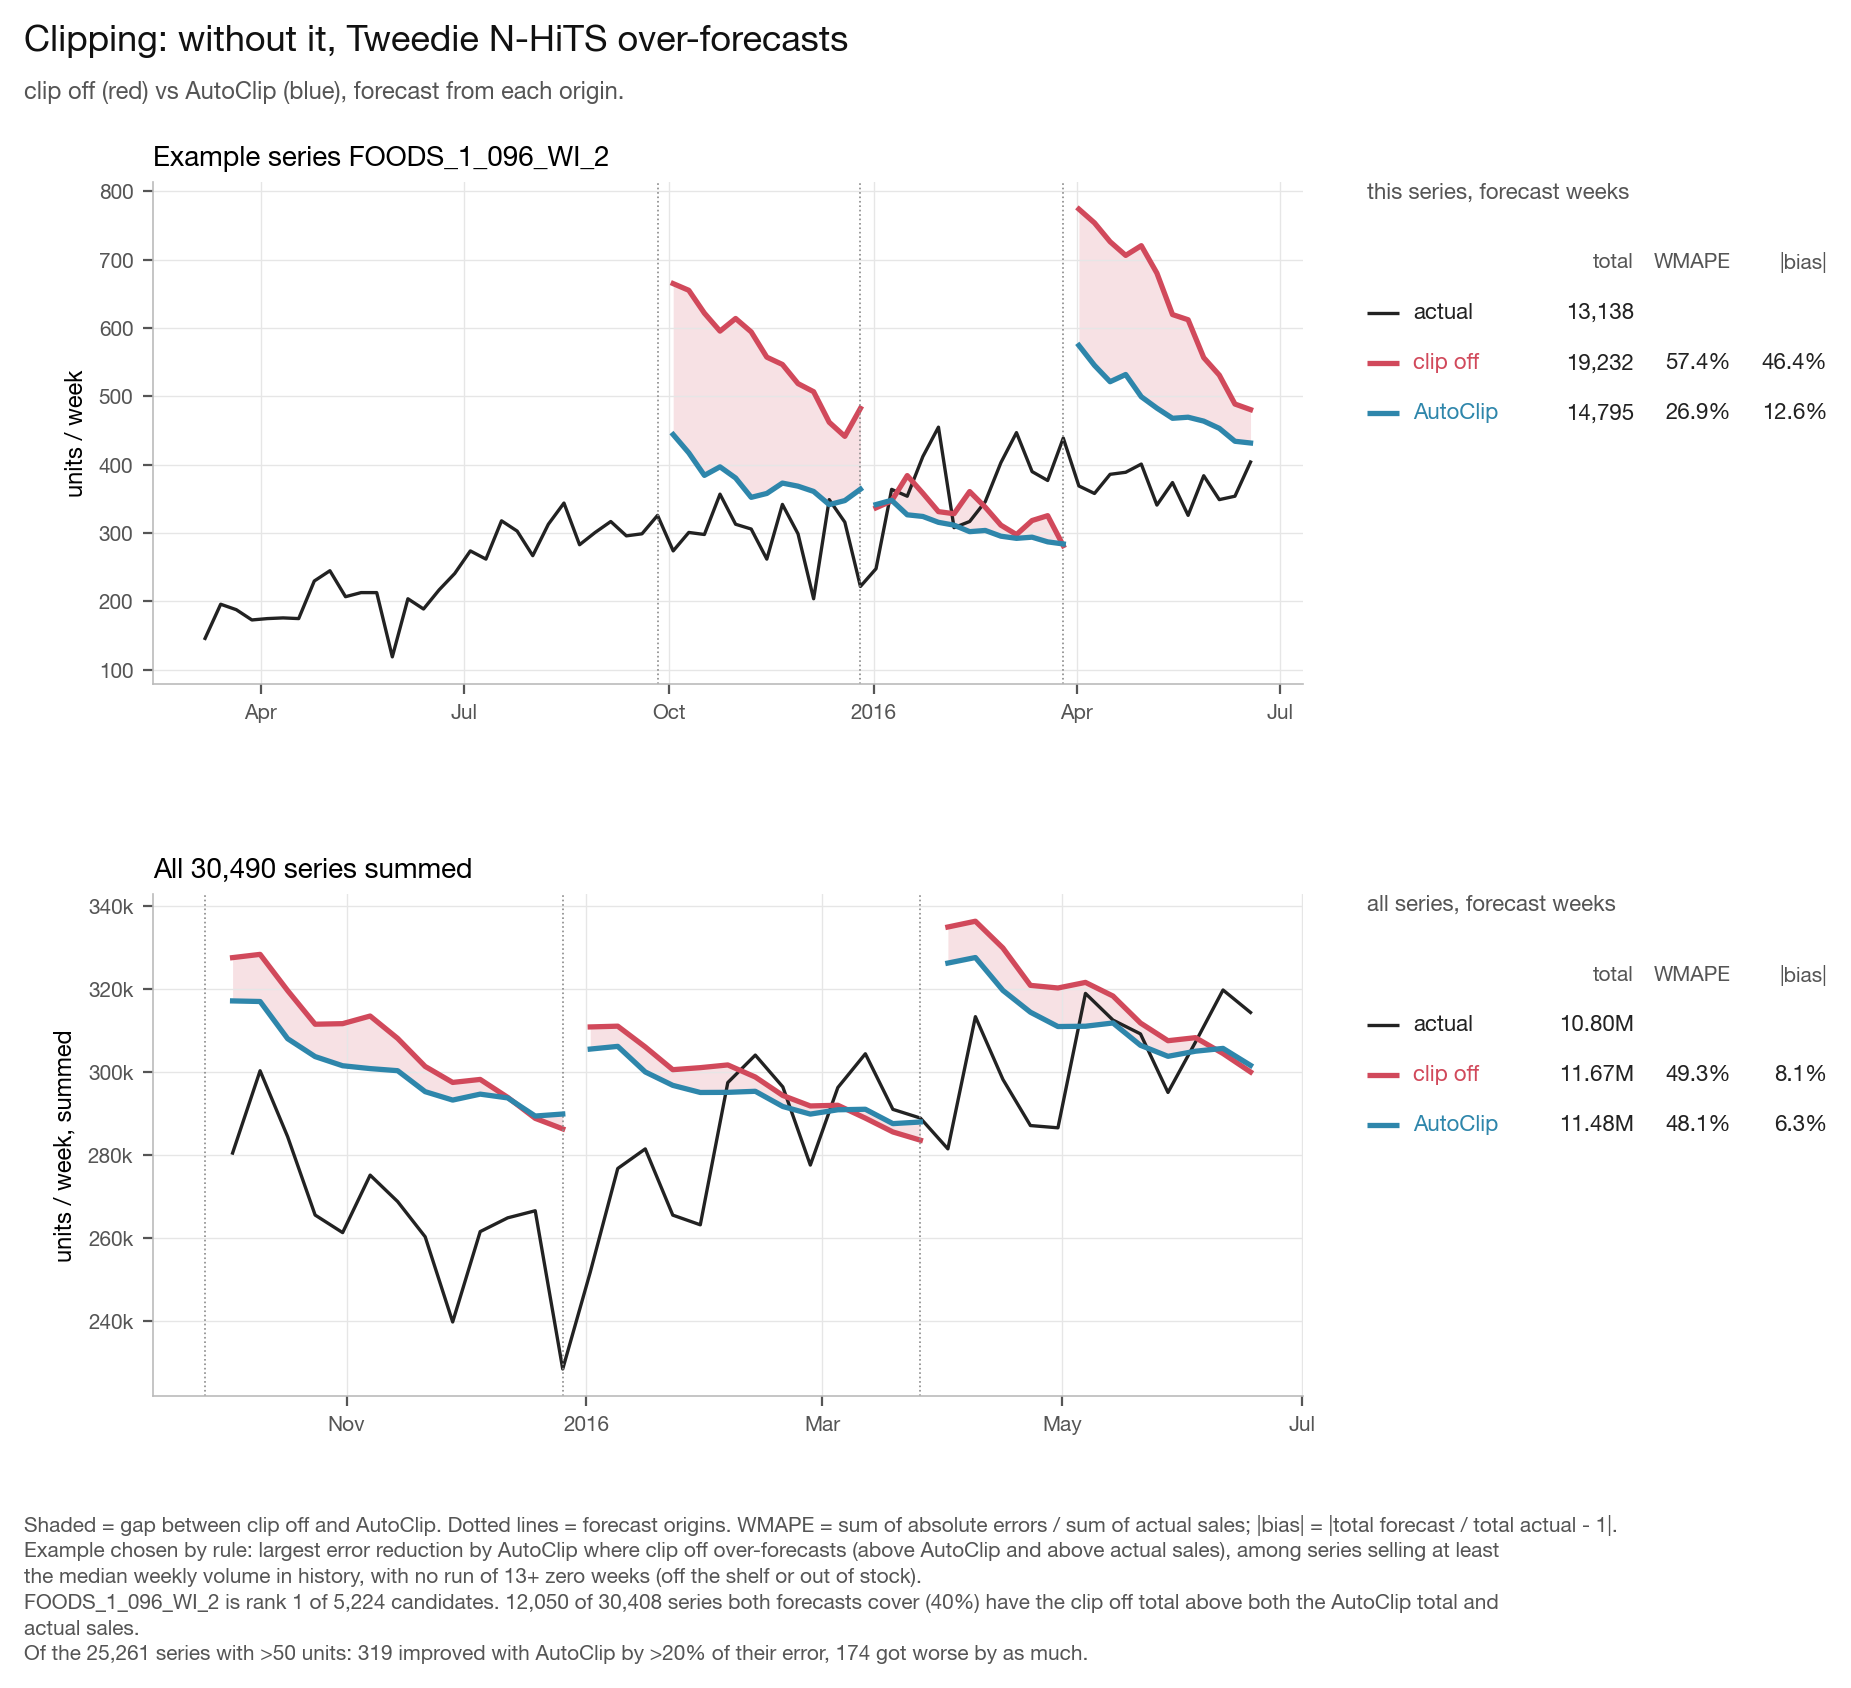

In [9]:
L = ("clip off", "AutoClip")
m_off, m_on = story.metrics("f2_noclip", R), story.metrics("f2_clip", R)
assert m_off["bias"] > max(m_on["bias"], 0), "title says clip off over-forecasts more; results changed"
t, p = section("f2_noclip", "f2_clip", examples.pick_overforecast_fix, L,
               "Clipping: without it, Tweedie N-HiTS over-forecasts", "story_clipping")

In [10]:
verdict_md("clipping", "f2_noclip", "f2_clip", L, p)
fo, fn = (results.load_run(a, R)["summary"]["fold_stats"][0] for a in ("f2_noclip", "f2_clip"))
spike = lambda f: f["grad_norm_max"] / f["grad_norm_median"]  # noqa: E731
display(Markdown(f"Without clipping, the largest gradient was {spike(fo):,.0f}× the median gradient norm. AutoClip scaled "
                 f"down {fn['grad_clip_frac']:.0%} of updates. Norms are recorded before clipping, so the clipped run's own "
                 f"ratio ({spike(fn):,.0f}×) describes the batches it saw, not the steps it took."))

All series: **clip off**: WMAPE 49.27, |bias| 8.1% (over-forecast) · **AutoClip**: WMAPE 48.14, |bias| 6.3% (over-forecast). Going from clip off to AutoClip: WMAPE -1.13, |bias| -1.7pt (seed noise ±0.2 WMAPE, ±1pt |bias|).

Verdict on clip off: **underfit and biased**. With clip off, these got worse: fit to the training history and week-to-week tracking (WMAPE +1.13). Total-volume bias was 1.7pt larger.

On FOODS_1_096_WI_2: clip off WMAPE 57.4, |bias| 46.4%; AutoClip WMAPE 26.9, |bias| 12.6%.

The example (FOODS_1_096_WI_2) is the rule's top case (rank 1 of 5,224 candidates). 12,050 of the 30,408 series both runs forecast (40%) have the clip off total above both the AutoClip total and actual sales. Of the 25,261 series selling more than 50 units, 319 got more than 20% better with AutoClip and 174 got worse by as much; on 3,673 of them the two forecasts differ by more than 10%. Large per-series changes go both ways, so the all-series result is a net effect, not a uniform one.

Without clipping, the largest gradient was 18× the median gradient norm. AutoClip scaled down 91% of updates. Norms are recorded before clipping, so the clipped run's own ratio (141×) describes the batches it saw, not the steps it took.

**What to set:** `callbacks=[AutoClip(clip_percentile=10)]` (from `m5knobs.model`) on the model. The alternative is Lightning's
fixed `gradient_clip_val=...`, passed as a model keyword, which needs a threshold chosen in advance. Keep clipping on with
Tweedie.

### 3.2 Input window: a full year lets the model use last year's pattern

**Claim.** Each training example is `input_size` past weeks followed by the 13 weeks to predict. A 13-week window cannot see
the same weeks last year, so the model falls back to the recent level.

**Example rule:** among series whose sales repeat last year's (top quartile of correlation between forecast-week sales and
the same weeks a year earlier) and that have no stock-outs, the series where the 52-week forecast follows last year's sales
most closely compared with the 13-week forecast.

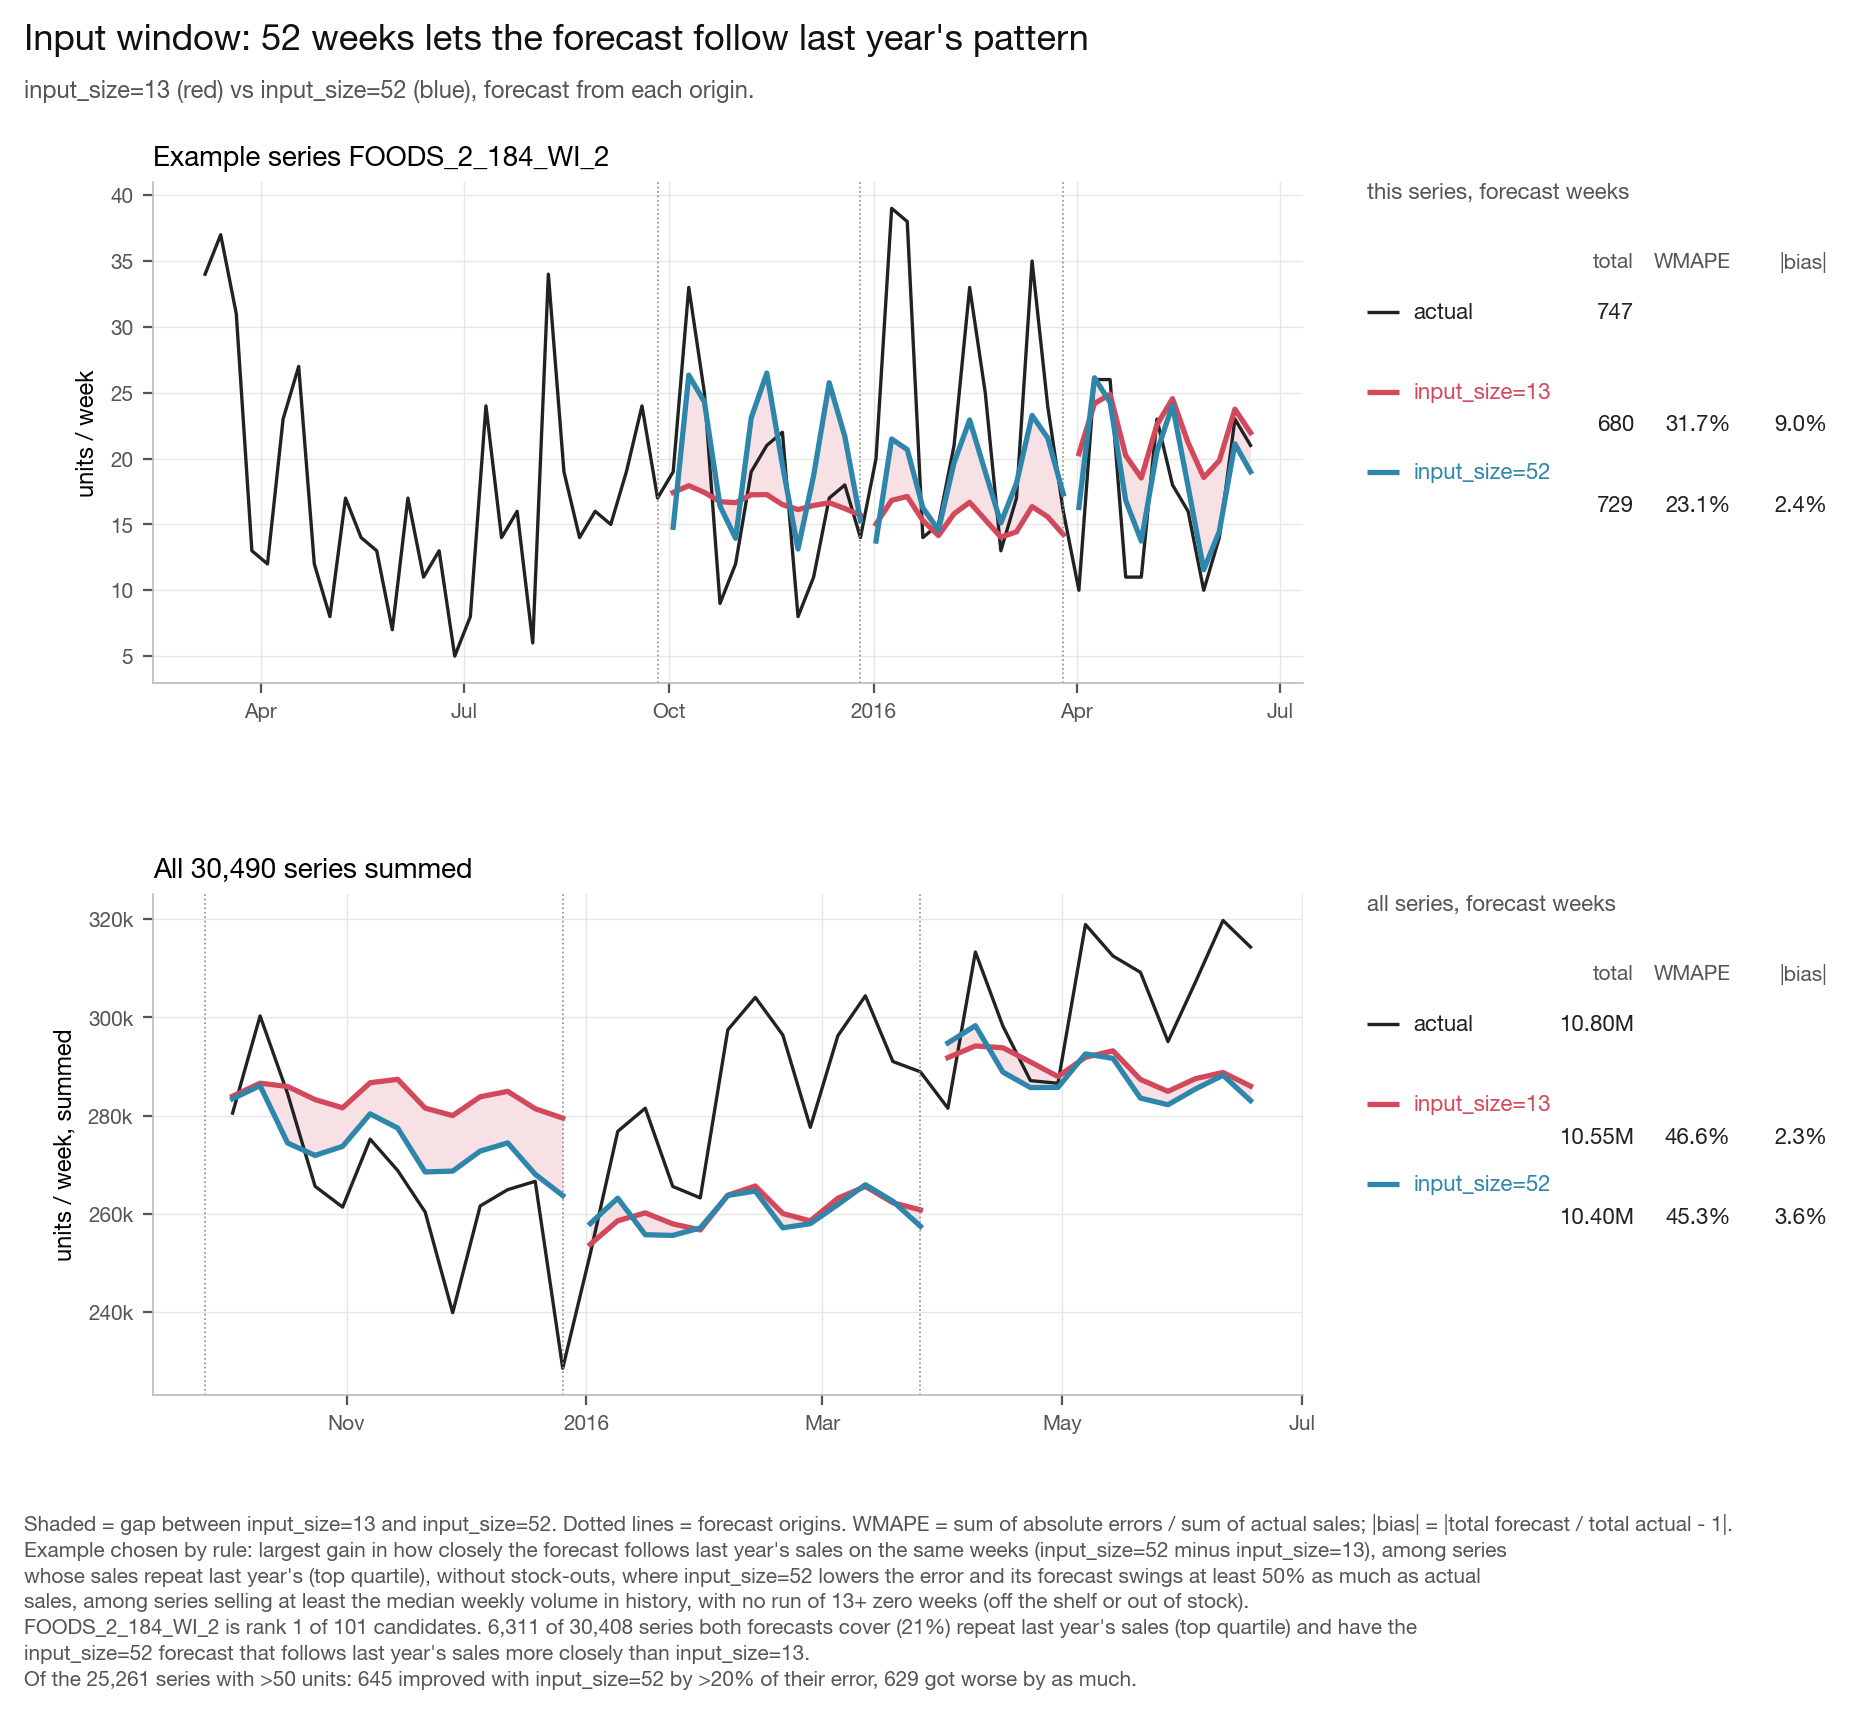

In [11]:
L = ("input_size=13", "input_size=52")
t, p = section("f3_input13", "f3_fix", examples.pick_seasonal_gain, L,
               "Input window: 52 weeks lets the forecast follow last year's pattern", "story_input_window")

In [12]:
verdict_md("input_size", "f3_input13", "f3_fix", L, p)

All series: **input_size=13**: WMAPE 46.57, |bias| 2.3% (under-forecast) · **input_size=52**: WMAPE 45.27, |bias| 3.6% (under-forecast). Going from input_size=13 to input_size=52: WMAPE -1.30, |bias| +1.4pt (seed noise ±0.2 WMAPE, ±1pt |bias|). On all series, input_size=13 has the smaller |bias| (2.3% vs 3.6%). Both under-forecast total volume, and the input_size=13 forecasts happen to sit higher, which lands closer to actual sales in total. Its week-by-week error is still larger (WMAPE 46.57 vs 45.27): a model can fit worse and still land closer in total by chance, which is why the verdict looks at fit and WMAPE, and |bias| separately.

Verdict on input_size = 13: **underfit**. With input_size = 13, these got worse: fit to the training history, week-to-week tracking and how much the forecast moves, which went flatter (WMAPE +1.30). Trade-off: bias moved from -2.3% to -3.6% with the fix (|bias| 1.4pt larger).

On FOODS_2_184_WI_2: input_size=13 WMAPE 31.7, |bias| 9.0%; input_size=52 WMAPE 23.1, |bias| 2.4%.

The example (FOODS_2_184_WI_2) is the rule's top case (rank 1 of 101 candidates). 6,311 of the 30,408 series both runs forecast (21%) repeat last year's sales (top quartile) and have the input_size=52 forecast that follows last year's sales more closely than input_size=13. Of the 25,261 series selling more than 50 units, 645 got more than 20% better with input_size=52 and 629 got worse by as much; on 16,899 of them the two forecasts differ by more than 10%. Large per-series changes go both ways, so the all-series result is a net effect, not a uniform one.

**What to set:** `input_size=52` for weekly data (one year). Shorten it only if your own data gives a reason.

### 3.3 Early stopping: too little patience stops early and flattens the forecast

**Claim.** Validation loss on intermittent demand is noisy and often plateaus before it improves again. A short patience
window quits on a plateau and leaves an underfit, flatter forecast. Both runs have the minimum-steps guard off, so patience is
the only difference.

**Example rule:** among series where the 250-step forecast swings at most 75% as much as the 1,000-step one, the largest
error cut that comes from the forecast's shape (both forecasts rescaled to actual sales).

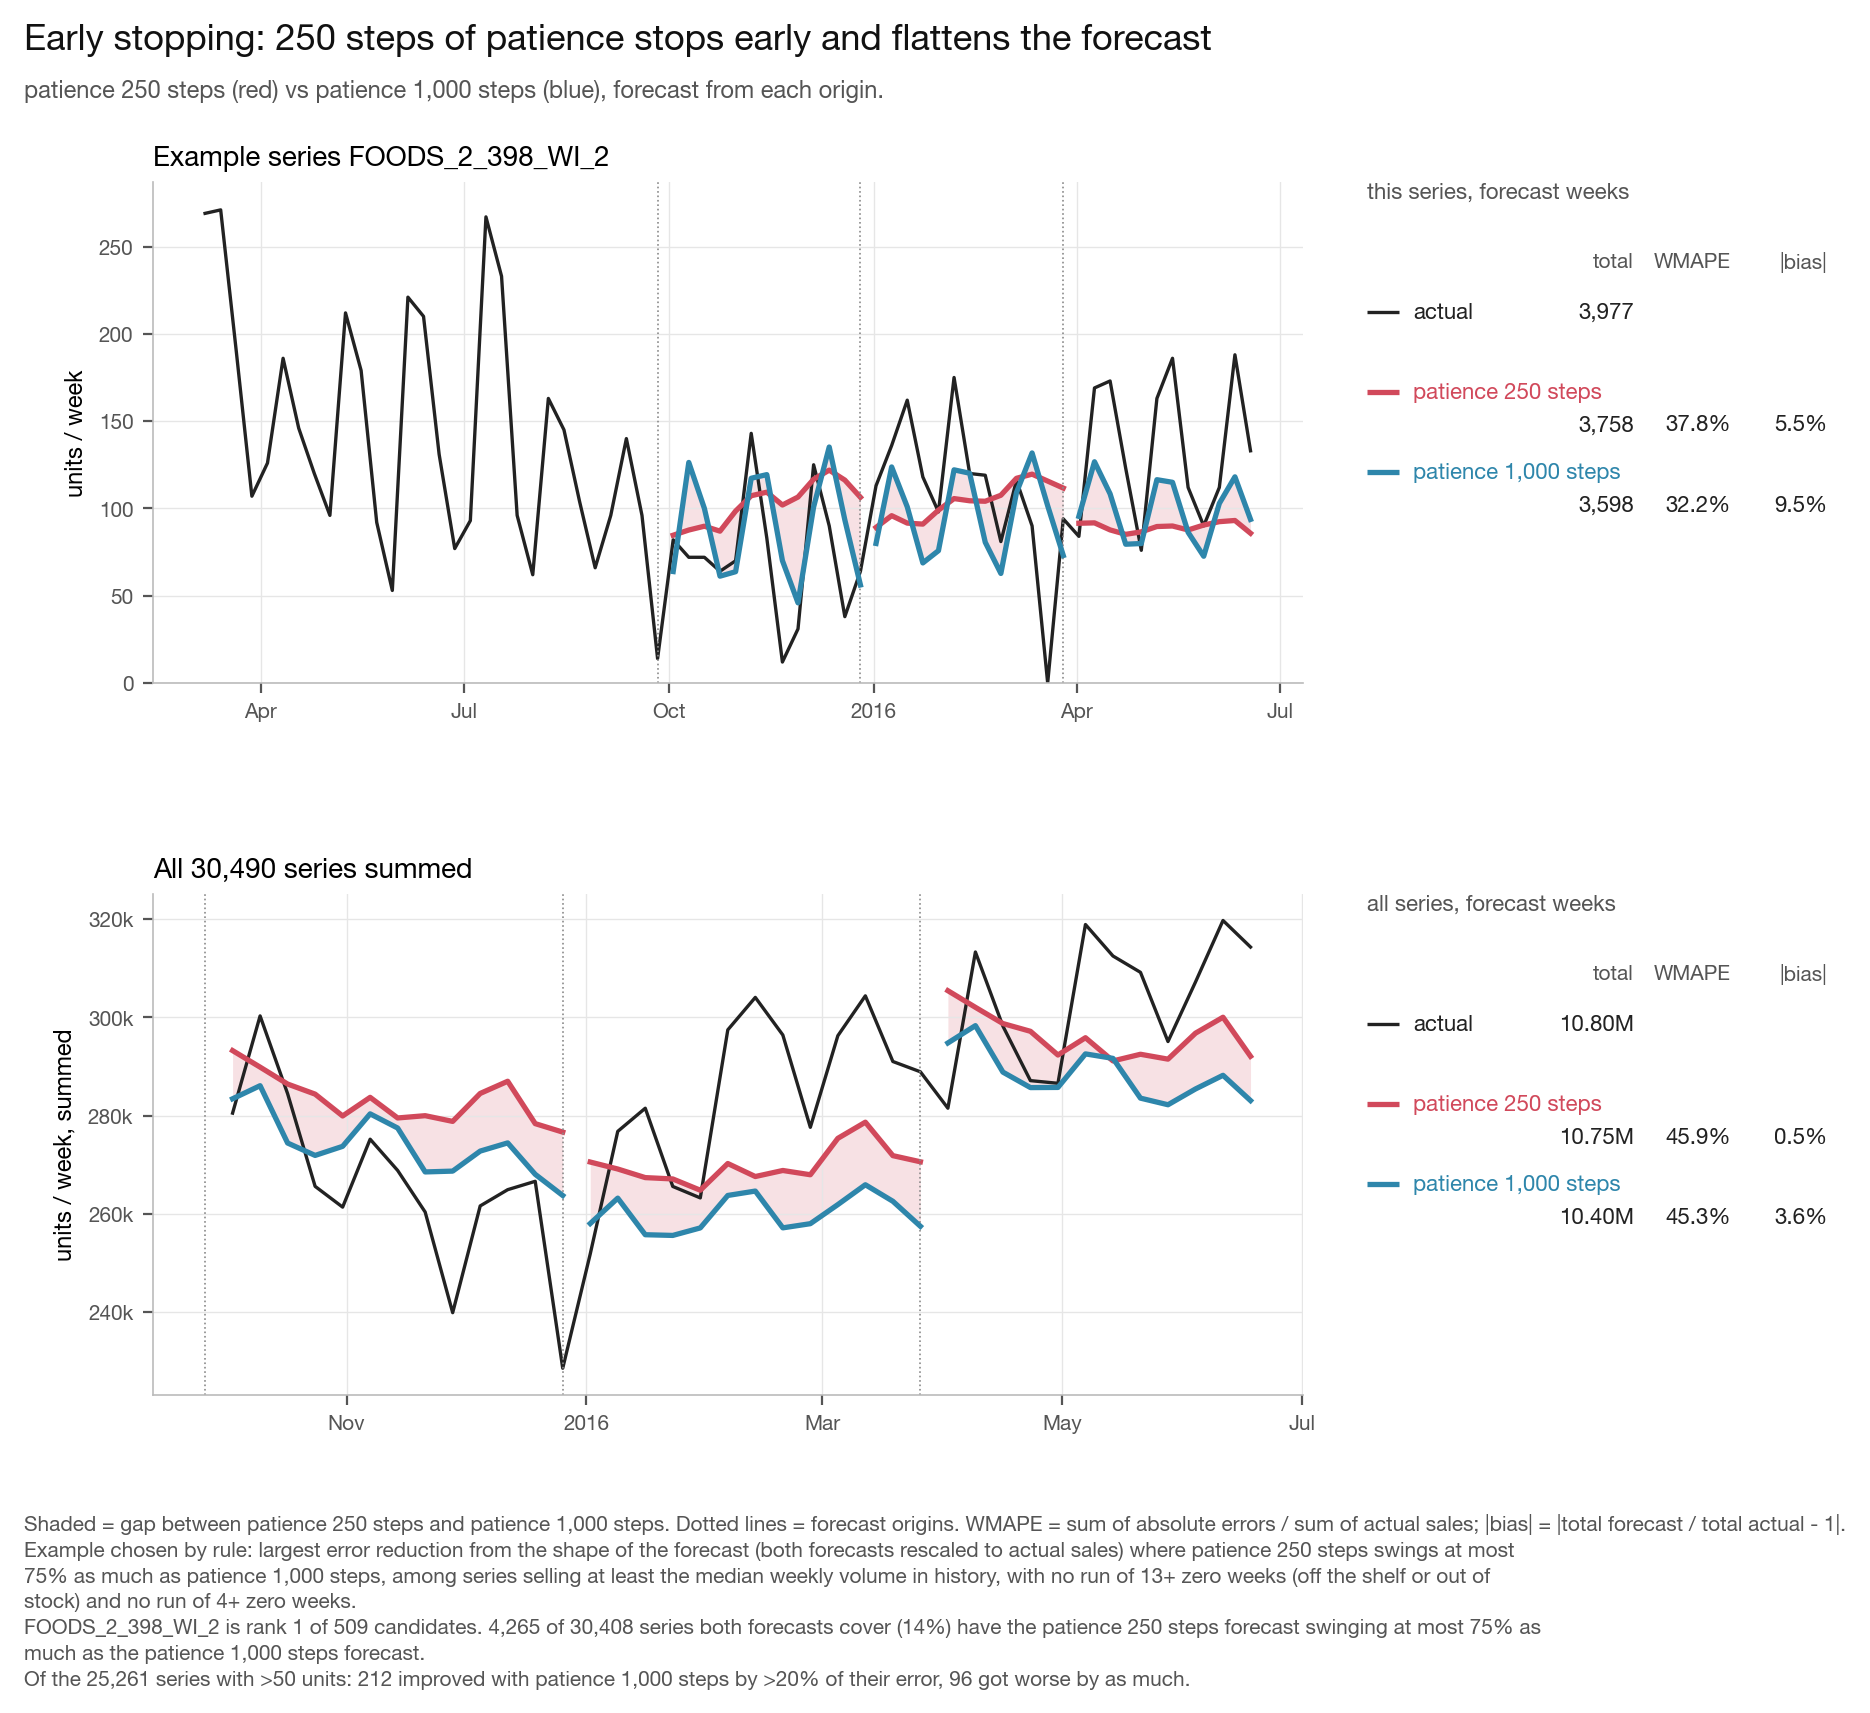

In [13]:
L = ("patience 250 steps", "patience 1,000 steps")
assert "flatter" in V["early_stopping"]["moved"], "title says the short window flattens the forecast; results changed"
t, p = section("f3_patience250", "f3_fix_noguard", examples.pick_flatter_wrong, L,
               "Early stopping: 250 steps of patience stops early and flattens the forecast", "story_early_stopping")

In [14]:
verdict_md("early_stopping", "f3_patience250", "f3_fix_noguard", L, p)
fs = {a: results.load_run(a, R)["summary"]["fold_stats"][0] for a in ("f3_patience250", "f3_fix_noguard")}
same = story.metrics("f3_fix", R) == story.metrics("f3_fix_noguard", R)
display(Markdown(" · ".join(f"{lab}: best check at step {fs[a]['best_step']:,.0f}, stopped at {fs[a]['stop_step']:,.0f}"
                            for lab, a in zip(L, fs)) + ". With 1,000 steps of patience the minimum-steps guard made "
                 + ("no difference: the recipe run `f3_fix` scored the same." if same else
                    f"a difference: WMAPE {story.metrics('f3_fix', R)['wmape']:.2f} with it vs "
                    f"{story.metrics('f3_fix_noguard', R)['wmape']:.2f} without.")))

All series: **patience 250 steps**: WMAPE 45.93, |bias| 0.5% (under-forecast) · **patience 1,000 steps**: WMAPE 45.27, |bias| 3.6% (under-forecast). Going from patience 250 steps to patience 1,000 steps: WMAPE -0.65, |bias| +3.2pt (seed noise ±0.2 WMAPE, ±1pt |bias|). On all series, patience 250 steps has the smaller |bias| (0.5% vs 3.6%). Both under-forecast total volume, and the patience 250 steps forecasts happen to sit higher, which lands closer to actual sales in total. Its week-by-week error is still larger (WMAPE 45.93 vs 45.27): a model can fit worse and still land closer in total by chance, which is why the verdict looks at fit and WMAPE, and |bias| separately.

Verdict on 5 × 50 = 250 steps: **underfit**. With 5 × 50 = 250 steps, these got worse: fit to the training history, week-to-week tracking and how much the forecast moves, which went flatter (WMAPE +0.65). Trade-off: bias moved from -0.5% to -3.6% with the fix (|bias| 3.2pt larger).

On FOODS_2_398_WI_2: patience 250 steps WMAPE 37.8, |bias| 5.5%; patience 1,000 steps WMAPE 32.2, |bias| 9.5%. On this series patience 250 steps has the smaller |bias|: the example was chosen by the rule above, which is about a different measure.

The example (FOODS_2_398_WI_2) is the rule's top case (rank 1 of 509 candidates). 4,265 of the 30,408 series both runs forecast (14%) have the patience 250 steps forecast swinging at most 75% as much as the patience 1,000 steps forecast. Of the 25,261 series selling more than 50 units, 212 got more than 20% better with patience 1,000 steps and 96 got worse by as much; on 8,639 of them the two forecasts differ by more than 10%.

patience 250 steps: best check at step 150, stopped at 400 · patience 1,000 steps: best check at step 1,500, stopped at 2,500. With 1,000 steps of patience the minimum-steps guard made no difference: the recipe run `f3_fix` scored the same.

A separate study gave every run the same longer schedule (one-cycle over 10,000 steps) and varied the patience window from
250 to 4,000 steps. Its best run, `es_p4000`, comes back in section 5. It is always labelled *best of 5 early-stopping
settings*, because it was picked after seeing the results.

In [15]:
S = early_stopping.sweep(R)  # also writes results/es_sweep.json
pt = early_stopping.patience_table(S)
display(pt.assign(abs_bias=pt.bias.abs()).rename(columns={"window": "patience (steps)", "wape": "WMAPE", "bias": "bias %",
                                                          "abs_bias": "|bias| %"}).round(2).set_index("patience (steps)"))
display(Markdown(early_stopping.headline_text(pt) + "."))

,arm,WMAPE,bias %,|bias| %
patience (steps),,,,
250,es_p250,45.71,-1.30,1.30
500,es_p500,45.71,-0.31,0.31
1000,es_p1000,45.15,-3.45,3.45
2000,es_p2000,45.05,-5.64,5.64
4000,es_p4000,44.92,-5.43,5.43


More patience: 4,000 steps gave WMAPE 44.92 vs 45.15 at 1,000, but bias -3.4% → -5.4%.

**What to set:** `early_stop_patience_steps=20, val_check_steps=50` (1,000 steps without improvement), and restore the best
weights (`BestWeights()`). Longer patience can trade WMAPE for bias, so check both.

### 3.4 Loss: MAE under-forecasts intermittent demand (a bias story)

**Claim.** MAE is minimized by the median. On an intermittent series the median week is often zero, so an MAE model
under-forecasts total volume. Huber sits between the median and the mean. Expect WMAPE to barely move and |bias| to move a
lot. The bottom panel of this figure sums the intermittent series only.

**Example rule:** among intermittent series (at least 30% zero weeks) selling more than 50 units but outside the top volume
quartile, where MAE forecasts below actual sales and below Huber at every origin, the series where Huber closes the largest
share of MAE's shortfall.

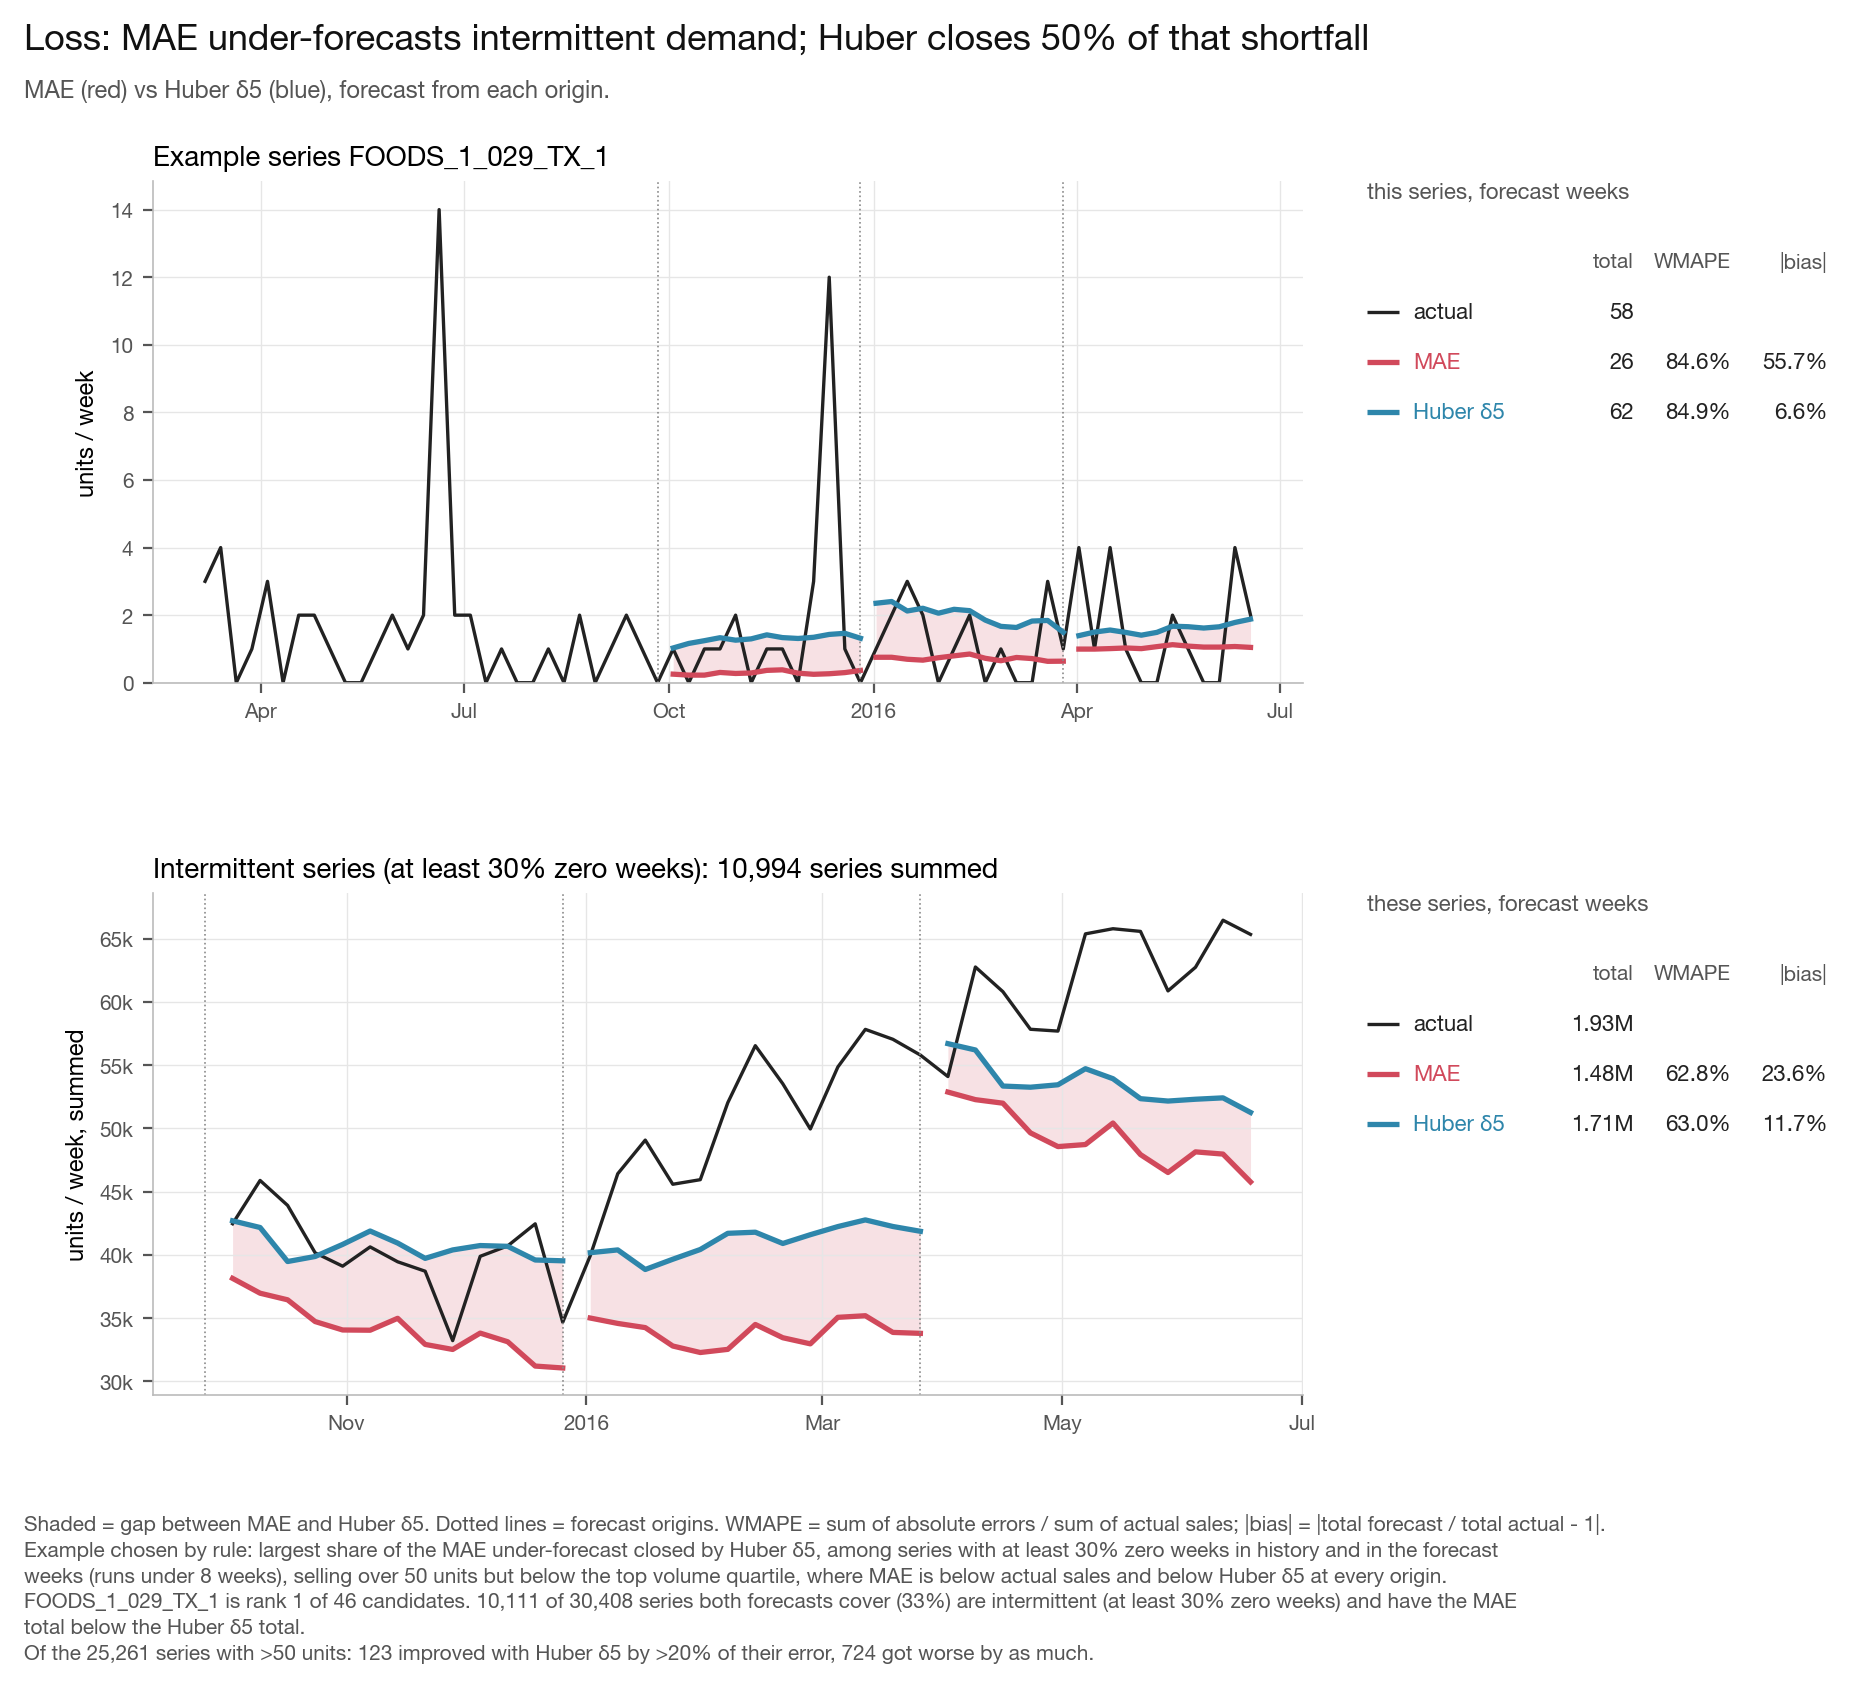

In [16]:
L = ("MAE", "Huber δ5")
t = examples.pair_table(R, "f3_mae", "f3_fix")
p = examples.pick_underforecast_wrong(t)
inter = t.unique_id[t.zero_share_hist >= 0.30]  # bottom panel: the intermittent series only
b = examples.bias_summary(t)  # intermittent series: at least 30% zero weeks in history
assert b["bias_wrong"] < min(b["bias_right"], 0), "title says MAE under-forecasts more; results changed"
closed = (b["bias_right"] - b["bias_wrong"]) / -b["bias_wrong"]
show(compare.draw(R, "f3_mae", "f3_fix", p, L, f"Loss: MAE under-forecasts intermittent demand; Huber closes {closed:.0%} "
                  "of that shortfall", "story_loss", population=inter, population_label="Intermittent series (at least 30% zero weeks)"))

In [17]:
verdict_md("loss", "f3_mae", "f3_fix", L, p)
display(Markdown(f"On the {b['n']:,} intermittent series, MAE forecasts below Huber on {b['share_wrong_below_right']:.0%} of "
                 f"them. Their total bias: **{b['bias_wrong']:+.1f}% with MAE vs {b['bias_right']:+.1f}% with Huber**. "
                 "Per-series WMAPE rewards forecasting the median, so judge this setting by bias."))

All series: **MAE**: WMAPE 45.45, |bias| 9.8% (under-forecast) · **Huber δ5**: WMAPE 45.27, |bias| 3.6% (under-forecast). Going from MAE to Huber δ5: WMAPE -0.18, |bias| -6.2pt (seed noise ±0.2 WMAPE, ±1pt |bias|).

Verdict on loss = MAE(): **biased**. Total-volume bias was 6.2pt larger.

On FOODS_1_029_TX_1: MAE WMAPE 84.6, |bias| 55.7%; Huber δ5 WMAPE 84.9, |bias| 6.6%. On this series MAE has the lower WMAPE: the example was chosen by the rule above, which is about a different measure.

The example (FOODS_1_029_TX_1) is the rule's top case (rank 1 of 46 candidates). 10,111 of the 30,408 series both runs forecast (33%) are intermittent (at least 30% zero weeks) and have the MAE total below the Huber δ5 total. Of the 25,261 series selling more than 50 units, 123 got more than 20% better with Huber δ5 and 724 got worse by as much; on 12,101 of them the two forecasts differ by more than 10%. More series got clearly worse than better with Huber δ5 on their own error.

On the 10,994 intermittent series, MAE forecasts below Huber on 92% of them. Their total bias: **-23.6% with MAE vs -11.7% with Huber**. Per-series WMAPE rewards forecasting the median, so judge this setting by bias.

**What to set:** `loss=HuberLoss(delta=5)` rather than `loss=MAE()` whenever total volume matters, as it does for stock
and supply plans. Tune `delta`, and check bias as well as WMAPE.

### 3.5 Scaler: no clear harm from MinMax on M5

**Claim tested.** MinMax lets one spike set a window's maximum and squeezes every other week toward zero. RevIN normalizes
each window by its mean and standard deviation instead. The verdict rule found no harm from MinMax on M5, so the figure
shows a *typical* series rather than an extreme one. Note that Huber δ5 is computed in scaled units, so on MinMax's [0, 1] scale it acts like squared error.

**Example rule:** the series with the median forecast change between the two runs.

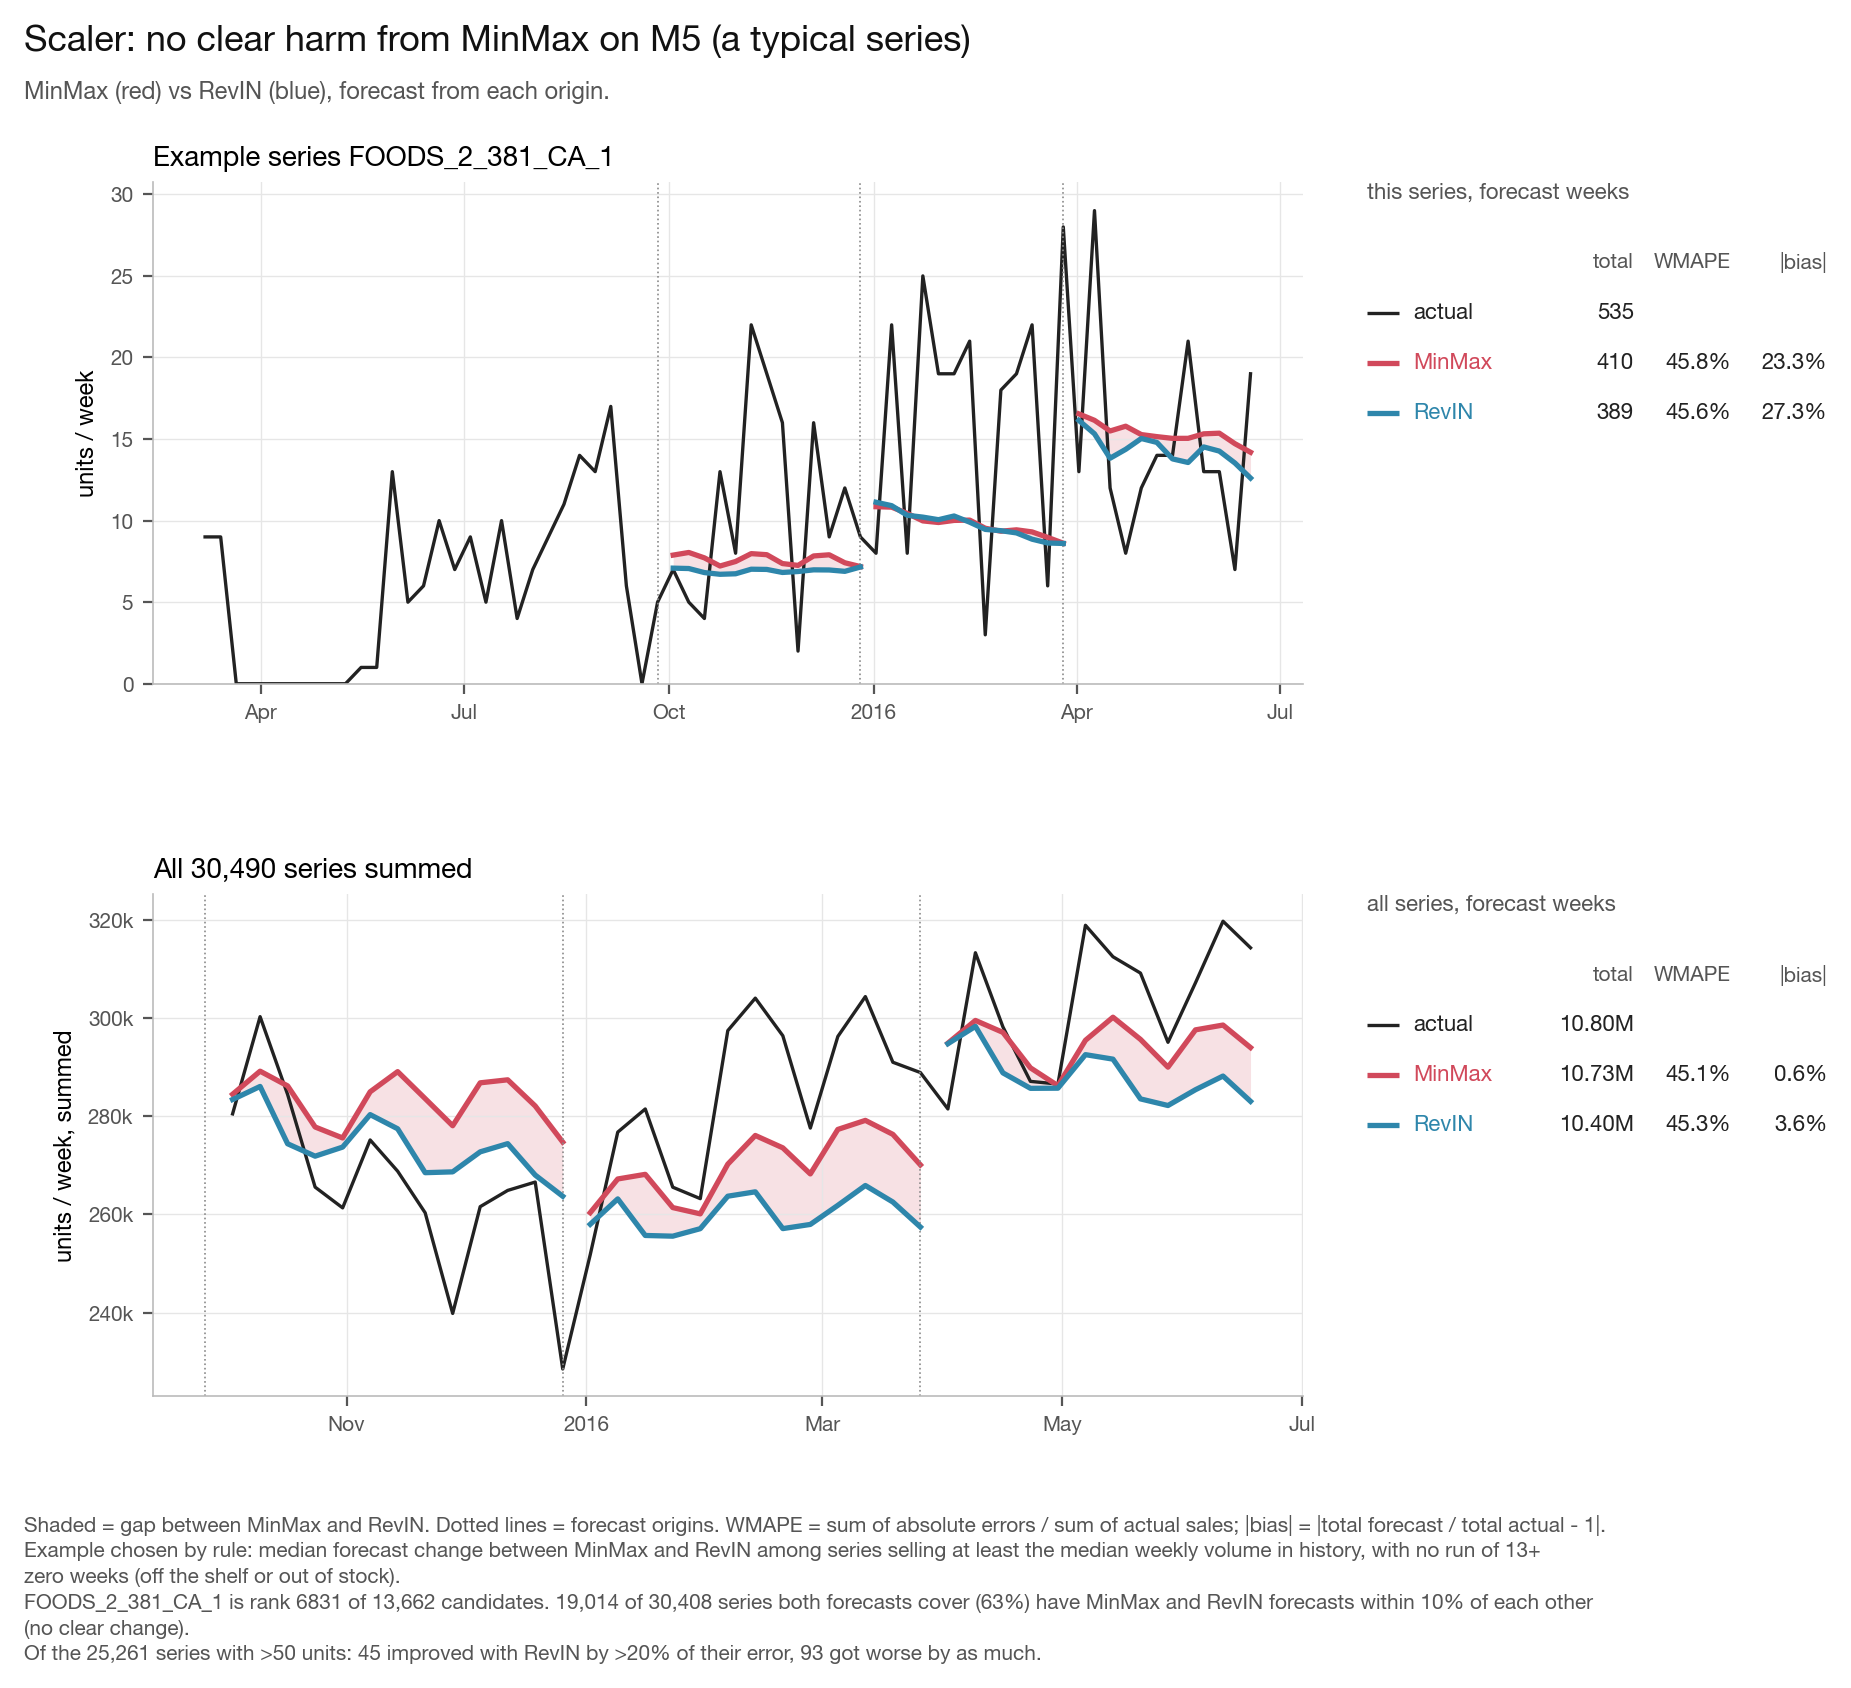

In [18]:
L = ("MinMax", "RevIN")
t, p = section("f3_minmax", "f3_fix", examples.pick_typical, L,
               "Scaler: no clear harm from MinMax on M5 (a typical series)", "story_scaler")

In [19]:
verdict_md("scaler", "f3_minmax", "f3_fix", L, p)

All series: **MinMax**: WMAPE 45.12, |bias| 0.6% (under-forecast) · **RevIN**: WMAPE 45.27, |bias| 3.6% (under-forecast). Going from MinMax to RevIN: WMAPE +0.15, |bias| +3.0pt (seed noise ±0.2 WMAPE, ±1pt |bias|). On all series, MinMax has the smaller |bias| (0.6% vs 3.6%). Both under-forecast total volume, and the MinMax forecasts happen to sit higher, which lands closer to actual sales in total. Its WMAPE is not worse either (45.12 vs 45.27).

Verdict on scaler_type = 'minmax': **no clear effect on M5**. Moved beyond seed noise without meeting the verdict rule: |bias| was 3.0pt smaller with scaler_type = 'minmax' (bias -0.6% vs -3.6%).

On FOODS_2_381_CA_1: MinMax WMAPE 45.8, |bias| 23.3%; RevIN WMAPE 45.6, |bias| 27.3%. On this series MinMax has the smaller |bias|: the example was chosen by the rule above, which is about a different measure.

The example (FOODS_2_381_CA_1) is a typical series, not an extreme one: the median forecast change (rank 6,831 of 13,662). 19,014 of the 30,408 series both runs forecast (63%) have MinMax and RevIN forecasts within 10% of each other (no clear change). Of the 25,261 series selling more than 50 units, 45 got more than 20% better with RevIN and 93 got worse by as much; on 7,037 of them the two forecasts differ by more than 10%. More series got clearly worse than better with RevIN on their own error.

In [20]:
mm, rv = story.metrics("f3_minmax", R), story.metrics("f3_fix", R)
wm_word = "not worse" if mm["wmape"] <= rv["wmape"] + data.SEED_NOISE["wape"] else "worse"
display(Markdown(f"**What to set:** `scaler_type=\"revin\"` is a common default, but this test did not show it is better. "
                 f"MinMax was {wm_word} on WMAPE ({mm['wmape']:.2f} vs {rv['wmape']:.2f} with RevIN) and its |bias| was "
                 f"{mm['abs_bias']:.1f}% vs {rv['abs_bias']:.1f}%. Compare scalers on your own data."))

**What to set:** `scaler_type="revin"` is a common default, but this test did not show it is better. MinMax was not worse on WMAPE (45.12 vs 45.27 with RevIN) and its |bias| was 0.6% vs 3.6%. Compare scalers on your own data.

### Did the settings matter?

Two claims practitioners often make, read against the five verdicts. Claim 1: a handful of training settings decide
whether deep learning works (read as: for most settings, the wrong value measurably hurts). Claim 2: getting them wrong
mostly makes the model underfit (read as: more than half of the verdicts are underfit).

In [21]:
display(pd.DataFrame([{"setting": c["name"], "wrong → right": f"{c['m_label']} → {c['f_label']}",
                       "verdict on the wrong value": label_text(V[c["key"]]["label"]),
                       "WMAPE wrong → right": f"{V[c['key']]['wape'][0]:.2f} → {V[c['key']]['wape'][1]:.2f}",
                       "|bias| wrong → right": f"{abs(V[c['key']]['bias'][0]):.1f}% → {abs(V[c['key']]['bias'][1]):.1f}%"}
                      for c in cards.CARDS]).set_index("setting"))
cl = cards.claims(V)
display(Markdown(f"- **Claim 1.** {cl['handful']}\n- **Claim 2.** {cl['underfit']}"))

,wrong → right,verdict on the wrong value,WMAPE wrong → right,|bias| wrong → right
setting,,,,
Gradient clipping,"clip off → AutoClip, 10th percentile",underfit and biased,49.27 → 48.14,8.1% → 6.3%
Input window,input_size = 13 → input_size = 52,underfit,46.57 → 45.27,2.3% → 3.6%
Early stopping,"5 × 50 = 250 steps → 20 × 50 = 1,000 steps",underfit,45.93 → 45.27,0.5% → 3.6%
Loss function,loss = MAE() → loss = HuberLoss(delta=5),biased,45.45 → 45.27,9.8% → 3.6%
Input scaling,scaler_type = 'minmax' → scaler_type = 'revin',no clear effect on M5,45.12 → 45.27,0.6% → 3.6%


- **Claim 1.** 4 of 5 cards gave the wrong value a verdict of underfit or biased: Gradient clipping, Input window, Early stopping and Loss function. Largest WMAPE gap among them: +1.30 (Input window, 2.9% of the 'with' run's WMAPE). Verdict on the claim, read as 'for most of the tested settings, the wrong value measurably hurts': holds.
- **Claim 2.** 3 of 5 cards gave the wrong value a verdict of underfit: Gradient clipping, Input window and Early stopping. Verdict on the claim, read as 'more than half of the cards are underfit': holds.

## 4. Clipping under stress

Claim 3: gradient clipping is non-negotiable for likelihood losses such as Tweedie. At the recipe's settings clipping
helped (3.1). Two other recipe settings may also limit gradient spikes: the low peak learning rate, and the short-history
filter. The stress test relaxes each one with clipping off and on. The stressors were fixed before any run.

This figure shows training, not forecasts. Left: gradient norm per step (red = clip off, blue = AutoClip, dashed = clip
threshold). Middle: validation loss. Right: WMAPE, bias and the outcome. A run *diverged* when its validation loss ended
above twice its best; that rule was set after seeing the results.

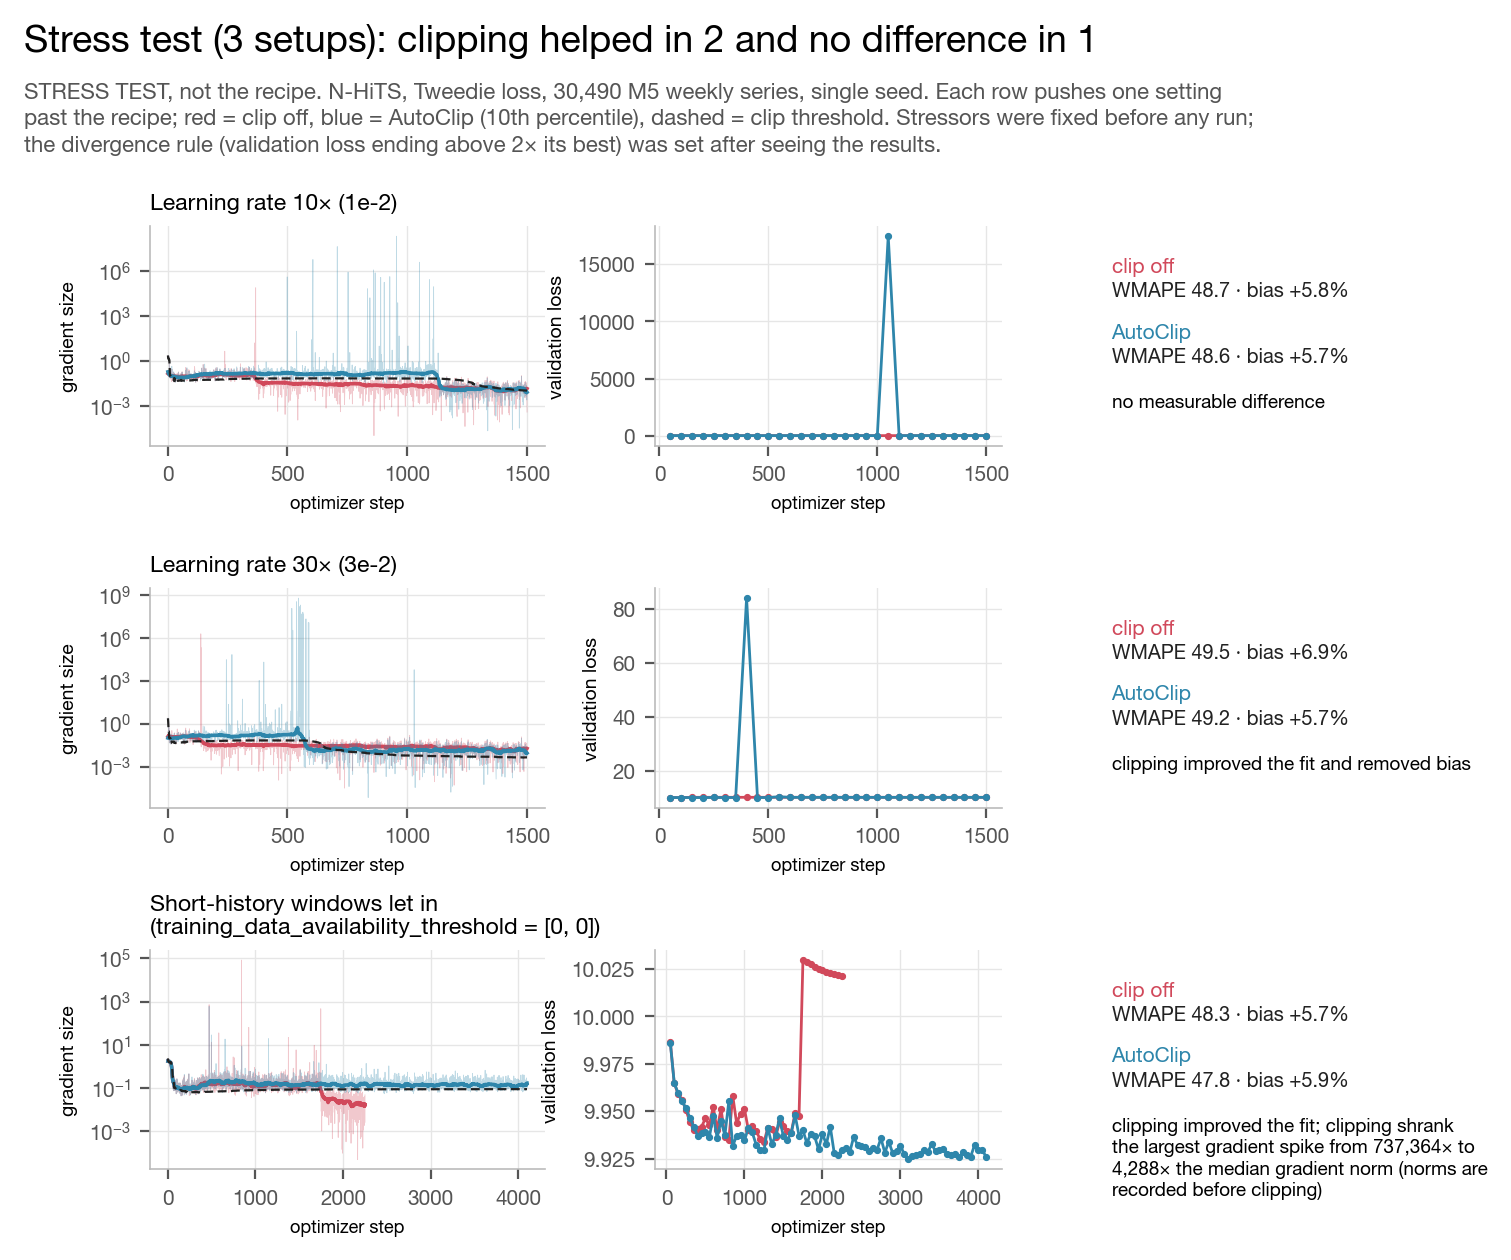

- Learning rate 10× (1e-2): WMAPE clip off 48.74, AutoClip 48.61.
- Learning rate 30× (3e-2): WMAPE clip off 49.51, AutoClip 49.17.
- Short-history windows let in: WMAPE clip off 48.33, AutoClip 47.83.

In [22]:
show(stress.draw(R))  # also writes results/stress_outcomes.json
O = json.load(open(os.path.join(R, "stress_outcomes.json")))
wm = lambda w: "crashed" if w is None else f"{w:.2f}"
display(Markdown("\n".join(f"- {stress.LABELS[k].splitlines()[0]}: WMAPE clip off {wm(o['off'])}, AutoClip {wm(o['on'])}."
                           for k, o in O.items())))

In [23]:
display(Markdown(f"**{stress.headline(O)}.**\n\n" + stress.conclusion(V["clipping"]["label"], O)))
sp = story.val_spikes(R)
spikes, spike_claim = story.spike_text(sp, {k: stress.LABELS[k].splitlines()[0] for k in sp})
display(Markdown(spikes + (" " + spike_claim if spike_claim else "")))

**Stress test (3 setups): clipping helped in 2 and no difference in 1.**

- At the recipe's settings, the card's verdict on clip off: underfit and biased.
- Learning rate 10× (1e-2): no measurable difference.
- Learning rate 30× (3e-2): neither diverged; the verdict on clip off was underfit and biased.
- Short-history windows let in: neither diverged; the verdict on clip off was underfit.
- Verdict on the claim: **holds** (recipe card: underfit and biased; in favour of clipping: clip off scored worse under the 30× learning rate and clip off scored worse with the short-history filter off).

Validation-loss spikes (peak above 2× the run's best): Learning rate 10× (1e-2): the AutoClip run spiked to 1,754.4× its best and recovered; Learning rate 30× (3e-2): the AutoClip run spiked to 8.5× its best and recovered; Short-history windows let in: no spike in either run. The larger spikes were in the AutoClip runs (Learning rate 10× (1e-2) and Learning rate 30× (3e-2)), not the unclipped ones. So the stress test does not show clipping preventing instability; clipping's case here rests on the recipe verdict and on where each run ended (WMAPE), not on calmer training.

**What to set:** keep AutoClip on. Log the gradient norm per step and compare its largest value with its median; that ratio
is the quickest check for spiky batches. If you raise the learning rate or relax the short-history filter, rerun with
clipping on and off and compare the validation curves.

## 5. Deep learning vs LightGBM

Claim 4: with the right settings, deep learning can match gradient-boosted trees. The models:

- **LightGBM** (`f4_lgbm`): direct (one model per lead week), with lags, rolling statistics and calendar features. It is
  **refit at every origin**.
- **N-HiTS Huber** (`f3_fix`): the recipe with Huber loss from section 3, **fit once** at the first origin. The later origins
  reuse those weights with newer inputs. This is the fair comparison: its settings come from section 3 and were not
  changed for this comparison, and the single fit, if anything, works against it.
- **N-HiTS Huber, best of 5 ES** (`es_p4000`): the best of the 5 early-stopping settings in 3.3, *picked with hindsight*.
  It is a ceiling, not a fair entrant.
- **N-HiTS Tweedie** and **TCN Tweedie** (`f4_nhits`, `f4_tcn`): the stock-Tweedie recipe, refit at every origin.

Δ and p are against LightGBM, from a paired bootstrap over series.

In [24]:
from m5knobs import baselines
lgbm = baselines.make_lgbm(seed=1).models["yhat"].get_params()
display(Markdown(f"LightGBM: `objective='{lgbm['objective']}'`, `tweedie_variance_power={lgbm['tweedie_variance_power']}`, "
                 f"`n_estimators={lgbm['n_estimators']}`, `num_leaves={lgbm['num_leaves']}`, lags 1–26, {data.H} models per "
                 f"origin (one per lead week), refit at each of the {data.NFOLDS} origins."))
gaps = segments.gap_rows(R)
fair = gaps[~gaps.model.isin(["LightGBM", "N-HiTS Huber, best of 5 ES"])]
assert fair.loc[fair.wape.idxmin(), "model"] == "N-HiTS Huber", "section 2 calls f3_fix the strongest fair deep model"
display(story.gap_table(gaps).set_index("model"))
display(Markdown(story.claim4(gaps)))

LightGBM: `objective='tweedie'`, `tweedie_variance_power=1.5`, `n_estimators=200`, `num_leaves=127`, lags 1–26, 13 models per origin (one per lead week), refit at each of the 3 origins.

,arm,WMAPE,bias %,|bias| %,Δ WMAPE vs LightGBM,p (WMAPE),Δ |bias| vs LightGBM,p (|bias|)
model,,,,,,,,
LightGBM,f4_lgbm,45.35,-7.4,7.4,NaN,,NaN,
N-HiTS Huber,f3_fix,45.27,-3.6,3.6,-0.07,0.305,-3.8,<0.001
"N-HiTS Huber, best of 5 ES",es_p4000,44.92,-5.4,5.4,-0.43,<0.001,-2.0,<0.001
N-HiTS Tweedie,f4_nhits,48.02,6.1,6.1,2.67,<0.001,-1.3,0.011
TCN Tweedie,f4_tcn,47.21,4.6,4.6,1.86,<0.001,-2.8,<0.001


Claim 4 ('deep learning can match gradient-boosted trees'), judged on N-HiTS Huber (`f3_fix`, the pre-set recipe, fit once) vs LightGBM (refit at every origin): WMAPE 45.27 vs 45.35 (gap -0.07, p = 0.305; seed noise ±0.2), |bias| 3.6% vs 7.4% (p < 0.001). Verdict: holds.

### 5.1 The stock Tweedie loss loses, and the floor is why

**Claim.** The stock Tweedie output link cannot forecast much below about one unit a week (the floor measured in section 2).
On mostly-zero series it forecasts about one a week where sales are close to zero. That adds error on those series, and
it lifts the total, which may or may not land closer to actual sales. The bottom panel sums the mostly-zero series only,
and the numbers below give both WMAPE and bias.

**Example rule:** among series with at least 50% zero weeks in history that sold under 0.5 units a week (but sold) in the
forecast weeks while N-HiTS Tweedie forecast 0.9–1.2 a week, the largest error cut by N-HiTS Huber.

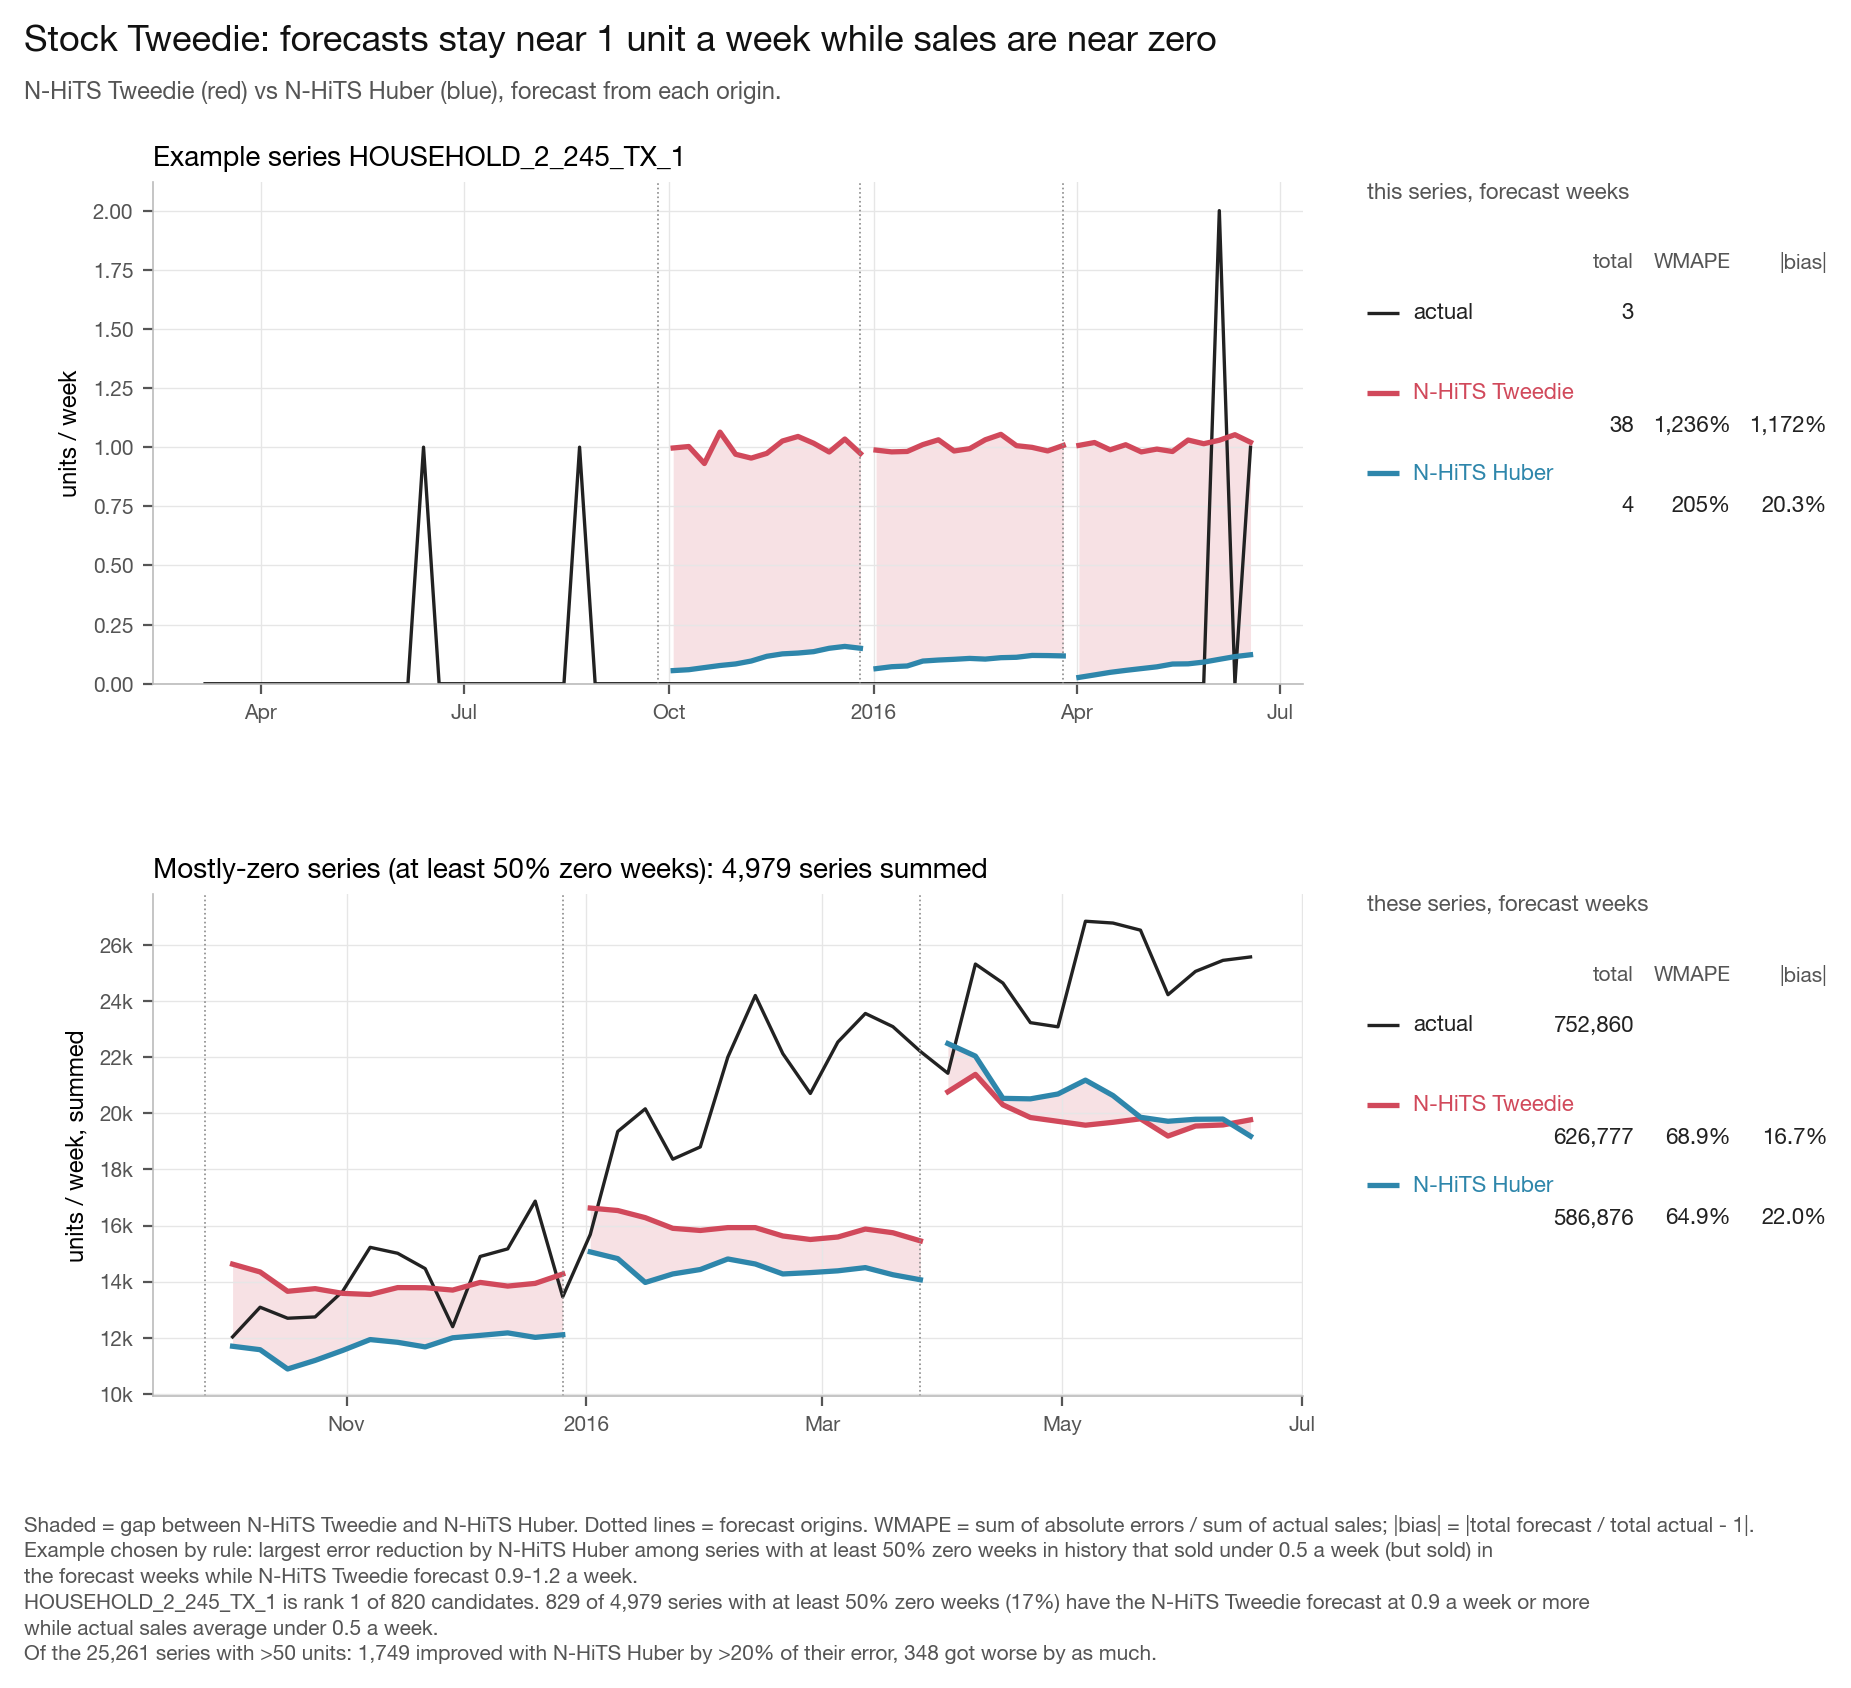

In [25]:
L = ("N-HiTS Tweedie", "N-HiTS Huber")
t = examples.pair_table(R, "f4_nhits", "f3_fix")
p = examples.pick_floor(t)
mostly_zero = t.unique_id[t.zero_share_hist >= 0.5]  # bottom panel: mostly-zero series only
show(compare.draw(R, "f4_nhits", "f3_fix", p, L, "Stock Tweedie: forecasts stay near 1 unit a week while sales are near zero",
                  "story_tweedie_floor", population=mostly_zero, population_label="Mostly-zero series (at least 50% zero weeks)"))

In [26]:
display(Markdown("\n\n".join([story.compare_line("f4_nhits", "f3_fix", L, R),
                                story.group_line(t, t.zero_share_hist >= 0.5, L, "Mostly-zero series (at least 50% zero weeks)"),
                                story.example_line(p, L), story.typical_line(p, L)])))
tw, hu = story.metrics("f2_clip", R), story.metrics("f3_fix", R)
lead_in = "Refitting is not what separates them" if tw["wmape"] - hu["wmape"] > data.SEED_NOISE["wape"] else     "Fit the same way, the gap mostly closes"
display(Markdown(f"{lead_in}: fit once like N-HiTS Huber, N-HiTS Tweedie (`f2_clip`) scores WMAPE "
                 f"{tw['wmape']:.2f} and bias {tw['bias']:+.1f}%, against {hu['wmape']:.2f} and {hu['bias']:+.1f}%."))

All series: **N-HiTS Tweedie**: WMAPE 48.02, |bias| 6.1% (over-forecast) · **N-HiTS Huber**: WMAPE 45.27, |bias| 3.6% (under-forecast). Going from N-HiTS Tweedie to N-HiTS Huber: WMAPE -2.74, |bias| -2.5pt (seed noise ±0.2 WMAPE, ±1pt |bias|).

Mostly-zero series (at least 50% zero weeks), counting only the series and weeks both models forecast (so the numbers differ slightly from the segment table): 4,979 series, 7% of volume. N-HiTS Tweedie WMAPE 68.90, |bias| 16.7% (under-forecast); N-HiTS Huber WMAPE 64.87, |bias| 22.0% (under-forecast). Series by series it is mixed: N-HiTS Huber has the lower error on 63% of them. The result splits by metric: N-HiTS Huber has the lower WMAPE (-4.03); N-HiTS Tweedie has the smaller |bias| (+5.3pt) (differences are N-HiTS Huber minus N-HiTS Tweedie). On these 4,979 series, N-HiTS Tweedie has the smaller |bias| (16.7% vs 22.0%). Both under-forecast total volume, and the N-HiTS Tweedie forecasts happen to sit higher, which lands closer to actual sales in total. Its week-by-week error is still larger (WMAPE 68.90 vs 64.87): a model can fit worse and still land closer in total by chance.

On HOUSEHOLD_2_245_TX_1: N-HiTS Tweedie WMAPE 1236.3, |bias| 1171.6%; N-HiTS Huber WMAPE 205.2, |bias| 20.3%.

The example (HOUSEHOLD_2_245_TX_1) is the rule's top case (rank 1 of 820 candidates). 829 of the 4,979 series with at least 50% zero weeks (17%) have the N-HiTS Tweedie forecast at 0.9 a week or more while actual sales average under 0.5 a week. Of the 25,261 series selling more than 50 units, 1,749 got more than 20% better with N-HiTS Huber and 348 got worse by as much; on 15,710 of them the two forecasts differ by more than 10%.

Refitting is not what separates them: fit once like N-HiTS Huber, N-HiTS Tweedie (`f2_clip`) scores WMAPE 48.14 and bias +6.3%, against 45.27 and -3.6%.

In [27]:
n_slow, vol_slow, slow = story.slow_seller_table(R)
display(Markdown(f"{n_slow:,} series sold under one unit a week in the year before the first origin. They hold "
                 f"{vol_slow:.1%} of scored volume. On them:"))
display(slow)
tw, hu = slow.loc["N-HiTS Tweedie"], slow.loc["N-HiTS Huber"]
assert tw["weekly forecasts under 0.9 units %"] < 1, "title says Tweedie forecasts stay near 1 unit a week"
display(Markdown(f"N-HiTS Tweedie forecasts under 0.9 units in {tw['weekly forecasts under 0.9 units %']:.1f}% of these "
                 f"series-weeks (median weekly forecast {tw['median weekly forecast']:.2f}). "
                 f"On these series that lifts its total (bias {tw['bias on these series %']:+.1f}% vs "
                 f"{hu['bias on these series %']:+.1f}% for Huber) but costs error: WMAPE {tw['WMAPE on these series']:.1f} vs "
                 f"{hu['WMAPE on these series']:.1f}."))

4,189 series sold under one unit a week in the year before the first origin. They hold 2.4% of scored volume. On them:

,WMAPE on these series,bias on these series %,median weekly forecast,weekly forecasts under 0.9 units %
model,,,,
LightGBM,78.2,-18.9,0.80,59.4
N-HiTS Huber,77.2,-25.5,0.68,66.9
"N-HiTS Huber, best of 5 ES",77.1,-26.4,0.67,68.5
N-HiTS Tweedie,82.1,-9.1,1.01,0.0
TCN Tweedie,81.7,-2.0,1.01,0.1


N-HiTS Tweedie forecasts under 0.9 units in 0.0% of these series-weeks (median weekly forecast 1.01). On these series that lifts its total (bias -9.1% vs -25.5% for Huber) but costs error: WMAPE 82.1 vs 77.2.

**What to set:** on mostly-zero weekly series, don't use stock `DistributionLoss("Tweedie")` unless you deal with its floor.
`HuberLoss(delta=5)` did better here.

### 5.2 Where N-HiTS Huber wins on total volume

**Question.** In which segments, and on which metric, does N-HiTS Huber beat LightGBM? In the figure, each bar is a deep
model's WMAPE or |bias| minus LightGBM's in one segment; left of zero means better than LightGBM, and * marks p < 0.05
within the segment (paired bootstrap over that segment's series; it covers series-to-series variation, not seed noise).
Segments come from the year before the first origin. The answer, computed under the table, comes first for total volume.

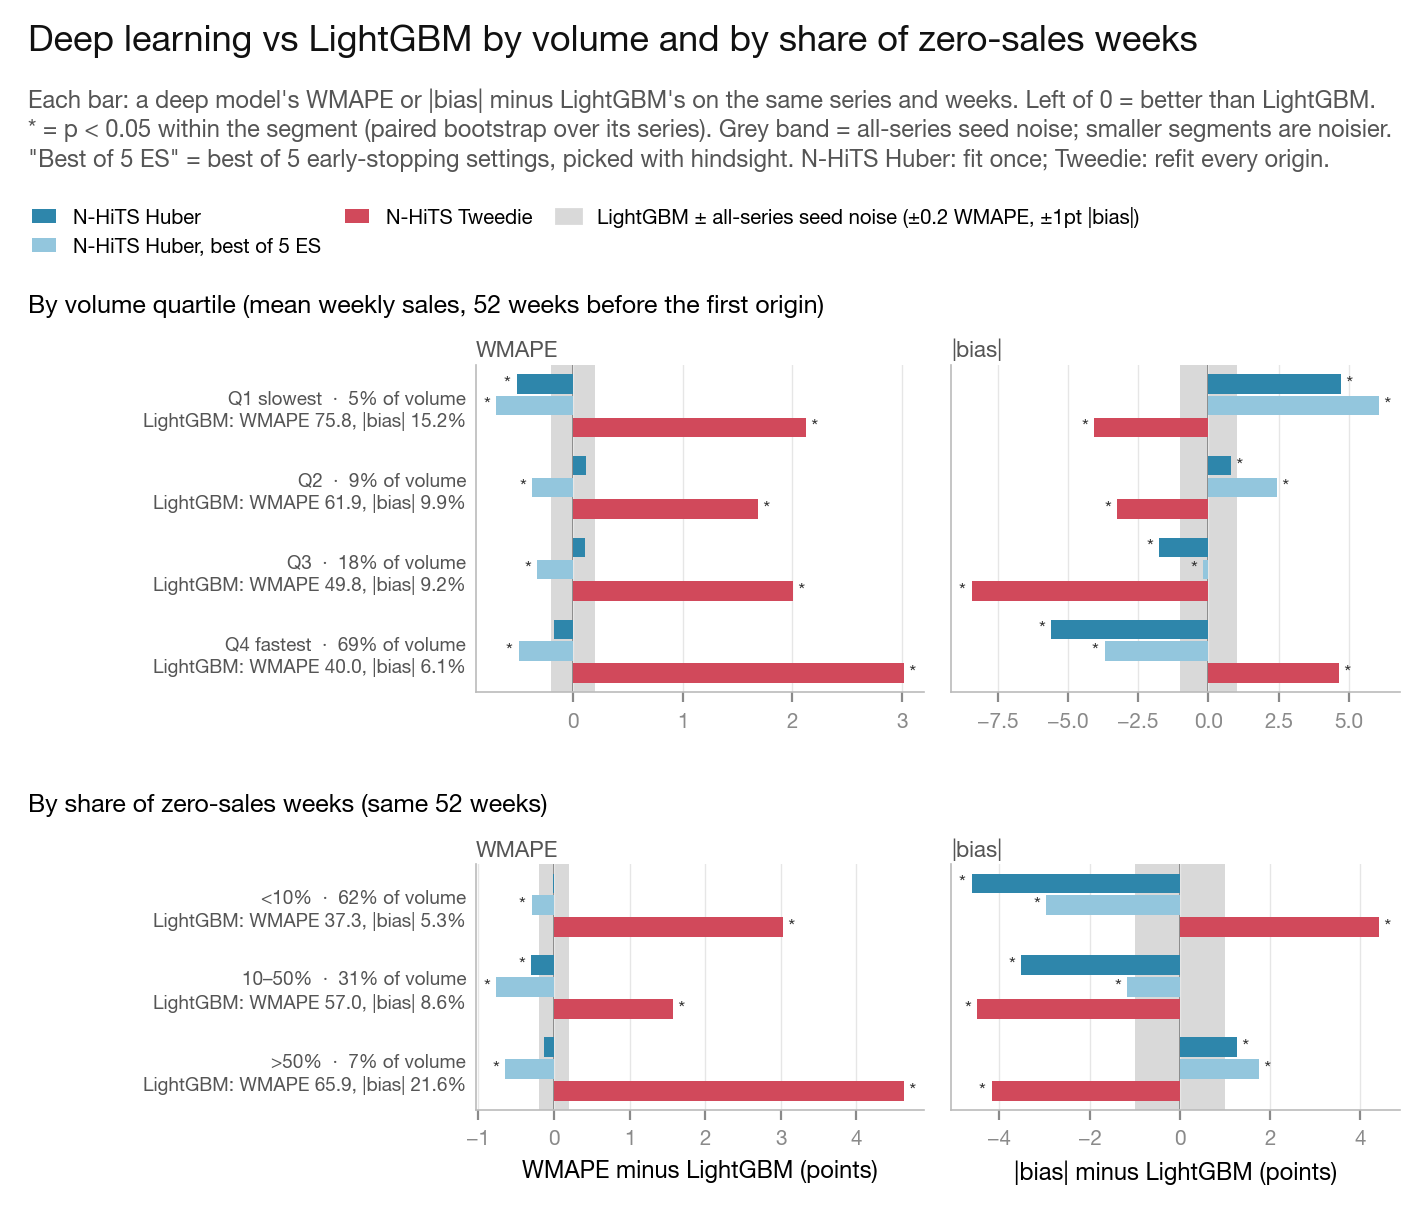

vol_share  wmape_dl  wmape_lgbm  d_wmape  p_wmape  \
segment_kind    segment                                                         
volume quartile Q1 slowest      0.047    75.292      75.807   -0.514    0.000   
                Q2              0.087    61.987      61.865    0.123    0.192   
                Q3              0.176    49.935      49.826    0.109    0.123   
                Q4 fastest      0.690    39.843      40.012   -0.169    0.122   
zero weeks      <10%            0.622    37.299      37.310   -0.012    0.883   
                10–50%          0.310    56.648      56.955   -0.307    0.047   
                >50%            0.066    65.805      65.932   -0.127    0.678   

                            absbias_dl  absbias_lgbm  d_absbias  p_absbias  \
segment_kind    segment                                                      
volume quartile Q1 slowest      19.905        15.206      4.699      0.000   
                Q2              10.699         9.886      0.813      0.000   
                Q3               7.468         9.215     -1.746      0.000   
                Q4 fastest       0.486         6.088     -5.601      0.000   
zero weeks      <10%             0.657         5.274     -4.616      0.000   
                10–50%           5.096         8.613     -3.517      0.000   
                >50%            22.901        21.619      1.282      0.003   

                                     wmape_read      bias_read  
segment_kind    segment                                         
volume quartile Q1 slowest        deep learning       LightGBM  
                Q2          no clear difference       LightGBM  
                Q3          no clear difference  deep learning  
                Q4 fastest  no clear difference  deep learning  
zero weeks      <10%        no clear difference  deep learning  
                10–50%            deep learning  deep learning  
                >50%        no clear difference       LightGBM

In [28]:
MODELS = ["LightGBM", "N-HiTS Huber", "N-HiTS Huber, best of 5 ES", "N-HiTS Tweedie"]
tab = segments.segment_table(R)
show(seg_fig.draw(tab, MODELS, kinds=story.STORY_KINDS, name="story_segments",
                  title="Deep learning vs LightGBM by volume and by share of zero-sales weeks"))
sg = story.segment_gaps(tab)
display(sg[sg.segment_kind.isin(story.STORY_KINDS)].round(3).set_index(["segment_kind", "segment"]))

In [29]:
h = gaps.set_index("model").loc["N-HiTS Huber"]
assert h.abs_bias_gap < -data.SEED_NOISE["bias"] and h.p_abs_bias < 0.05, "section title says N-HiTS wins on total volume"
best = sg[sg.segment_kind.isin(story.SERIES_KINDS) & (sg.bias_read == "deep learning")].sort_values("d_absbias").iloc[0]
wm = "ties" if abs(h.gap) <= data.SEED_NOISE["wape"] else "beats" if h.gap < 0 else "trails"
display(Markdown(f"Across all series N-HiTS Huber {wm} LightGBM on WMAPE ({h.gap:+.2f}, {segments.p_text(h.p)}) and has "
                 f"{-h.abs_bias_gap:.1f}pt less |bias| ({segments.p_text(h.p_abs_bias)}). Its largest clear |bias| advantage "
                 f"is in {story.segment_name(best)}: {best.d_absbias:+.1f}pt. The example below is from the fast, steady sellers "
                 "(top volume quartile and under 10% zero weeks)."))

Across all series N-HiTS Huber ties LightGBM on WMAPE (-0.07, p = 0.305) and has 3.8pt less |bias| (p < 0.001). Its largest clear |bias| advantage is in volume Q4 fastest (69% of volume): -5.6pt. The example below is from the fast, steady sellers (top volume quartile and under 10% zero weeks).

**Example rule:** among fast (top volume quartile), steady (under 10% zero weeks) series, the one where N-HiTS Huber's
total lands within 10% of actual sales and cuts LightGBM's miss on total volume the most (as a share of actual sales).
Candidates must be steady and long-lived: no run of 4 or more zero weeks and no week under 10% of the series' median
sales (in history or the forecast weeks), a full year of history before the first origin (so LightGBM's lag features are
filled), and forecast-week sales within 2/3 to 1.5 times the history level (no level shift). The bottom panel sums the fast, steady sellers only.

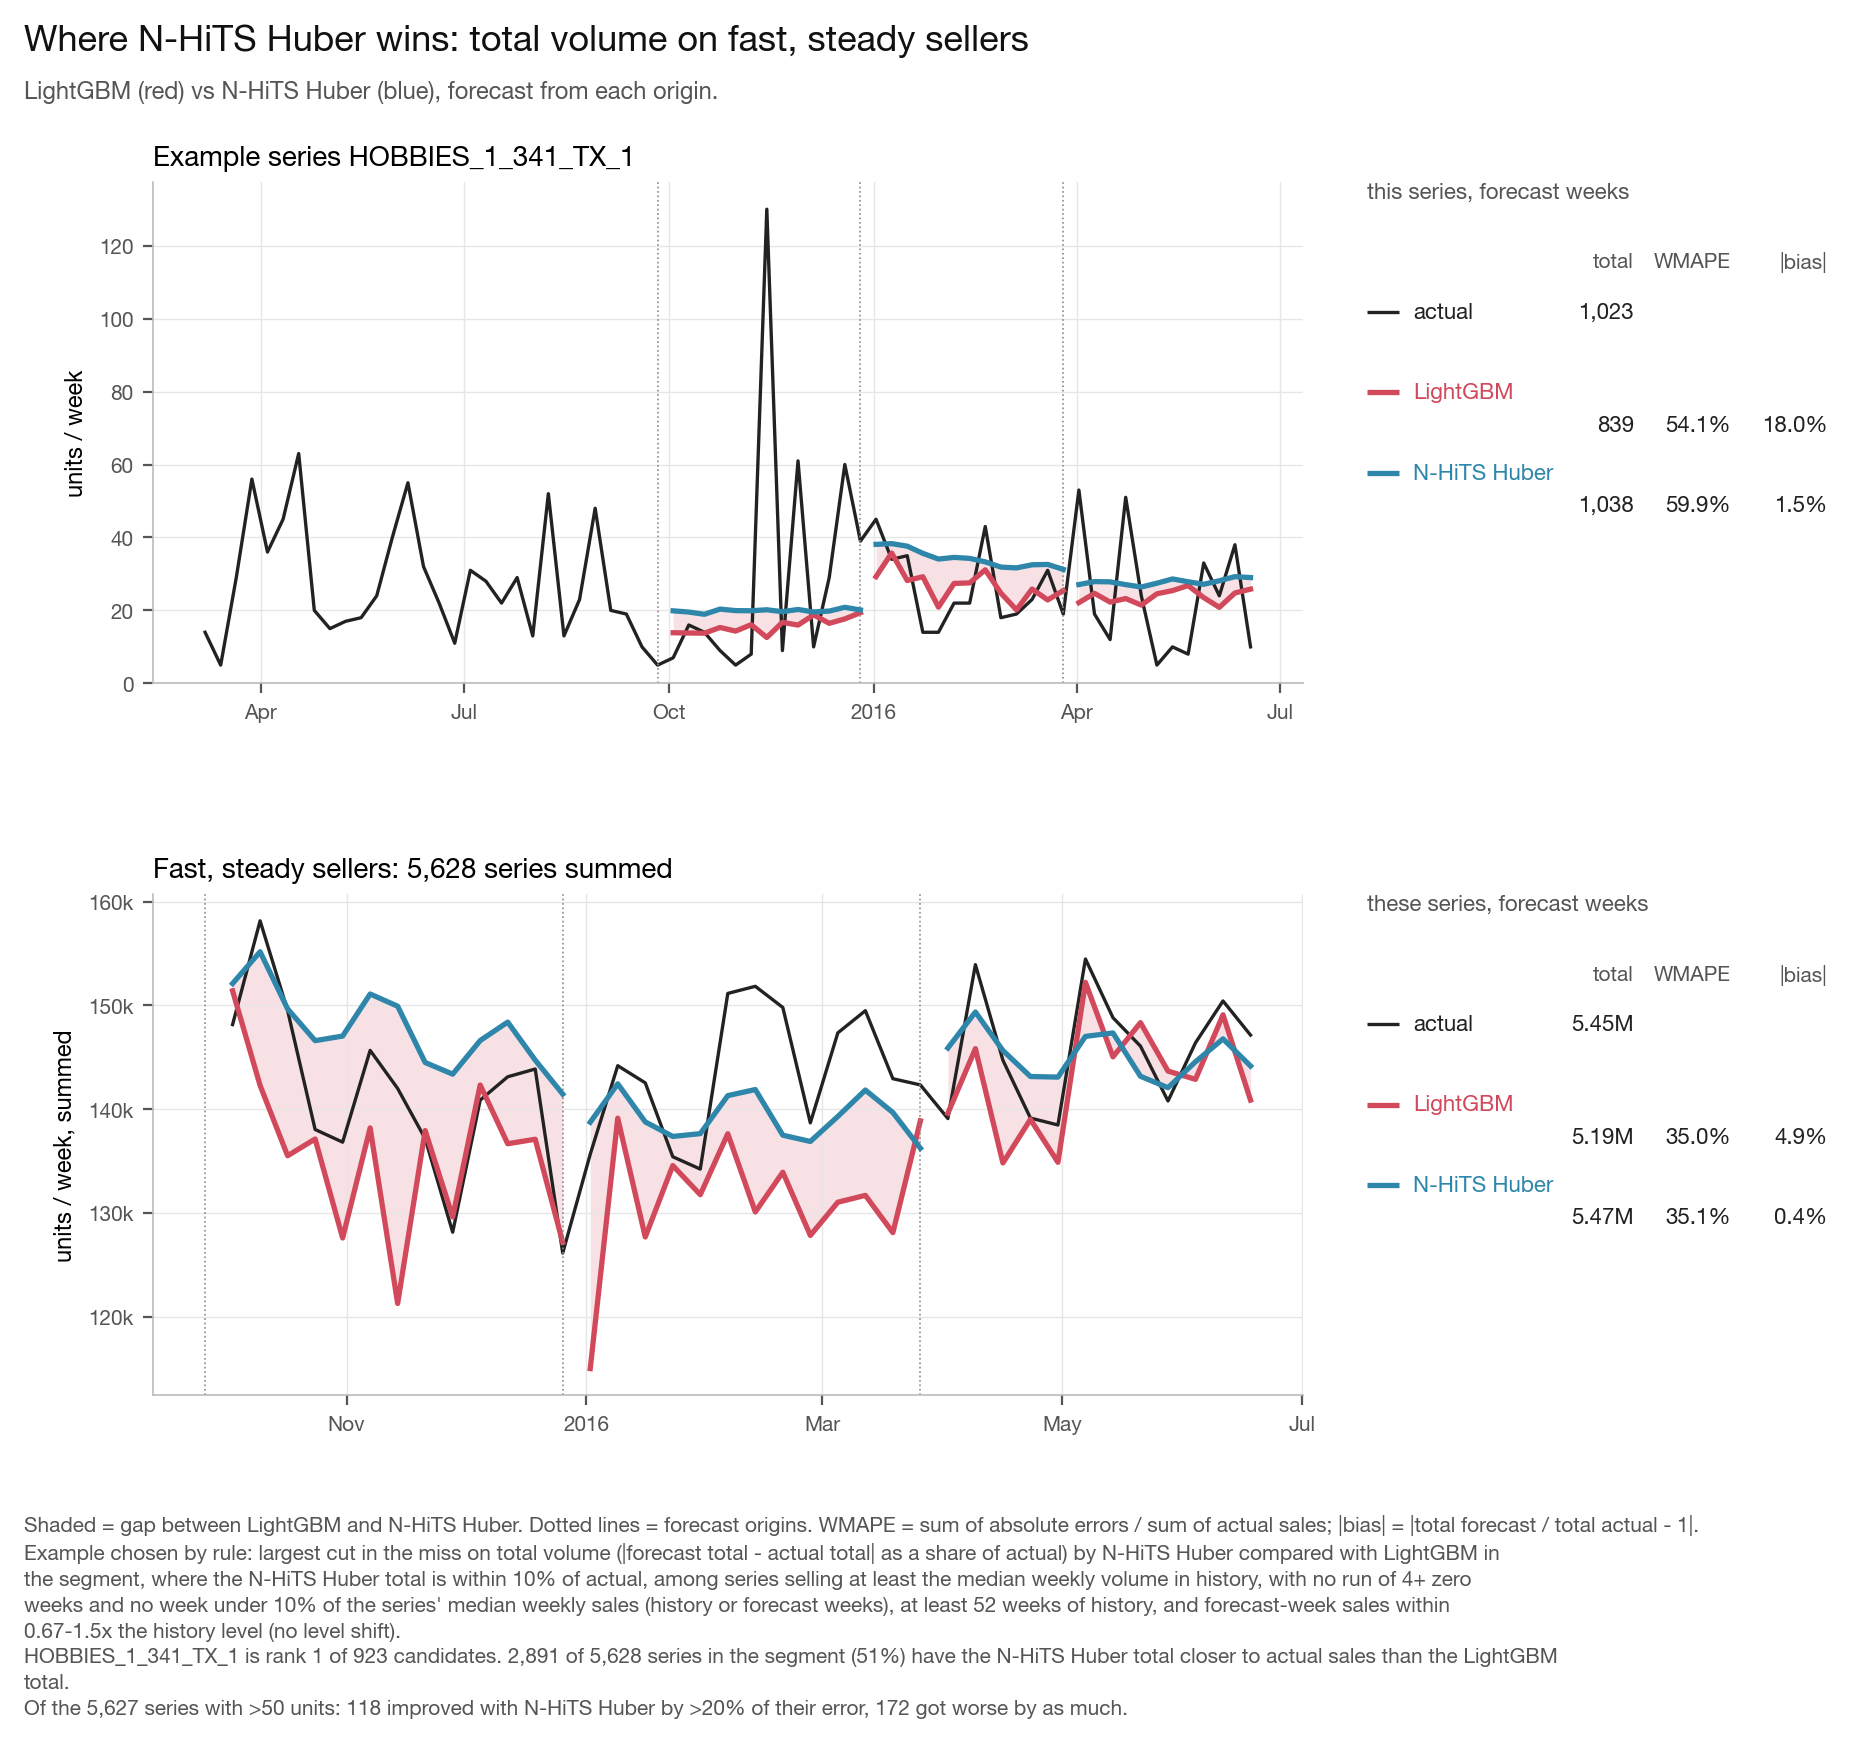

In [30]:
L = ("LightGBM", "N-HiTS Huber")
tl = examples.pair_table(R, "f4_lgbm", "f3_fix")
seg = segments.series_segments(R).set_index("unique_id")
steady = (seg["volume quartile"] == "Q4 fastest") & (seg["zero weeks"] == "<10%")
p = examples.pick_right_closer_total(tl, steady)
show(compare.draw(R, "f4_lgbm", "f3_fix", p, L, "Where N-HiTS Huber wins: total volume on fast, steady sellers",
                  "story_dl_wins", population=seg.index[steady], population_label="Fast, steady sellers"))

In [31]:
display(Markdown("\n\n".join([story.group_line(tl, steady, L, "Fast, steady sellers"), story.example_line(p, L),
                                story.typical_line(p, L)])))

Fast, steady sellers, counting only the series and weeks both models forecast (so the numbers differ slightly from the segment table): 5,628 series, 51% of volume. LightGBM WMAPE 35.03, |bias| 4.9% (under-forecast); N-HiTS Huber WMAPE 35.06, |bias| 0.4% (over-forecast). Series by series it is mixed: N-HiTS Huber has the lower error on 52% of them. By metric: WMAPE is a tie (within ±0.2: +0.02); N-HiTS Huber has the smaller |bias| (-4.5pt) (differences are N-HiTS Huber minus LightGBM).

On HOBBIES_1_341_TX_1: LightGBM WMAPE 54.1, |bias| 18.0%; N-HiTS Huber WMAPE 59.9, |bias| 1.5%. On this series LightGBM has the lower WMAPE: the example was chosen by the rule above, which is about a different measure.

The example (HOBBIES_1_341_TX_1) is the rule's top case (rank 1 of 923 candidates). 2,891 of the 5,628 series in the segment (51%) have the N-HiTS Huber total closer to actual sales than the LightGBM total. Of the 5,627 series selling more than 50 units, 118 got more than 20% better with N-HiTS Huber and 172 got worse by as much; on 1,531 of them the two forecasts differ by more than 10%. More series got clearly worse than better with N-HiTS Huber on their own error.

### 5.3 Where N-HiTS Huber wins on WMAPE

**Question.** Is there a series segment (by volume, zero weeks or department) where N-HiTS Huber has a clear WMAPE lead
(p < 0.05 within the segment)? The code takes the largest such lead. The example is N-HiTS Huber's largest WMAPE advantage
in that segment among steady series (the same stock-out, full-history and level-shift filters as in 5.2).

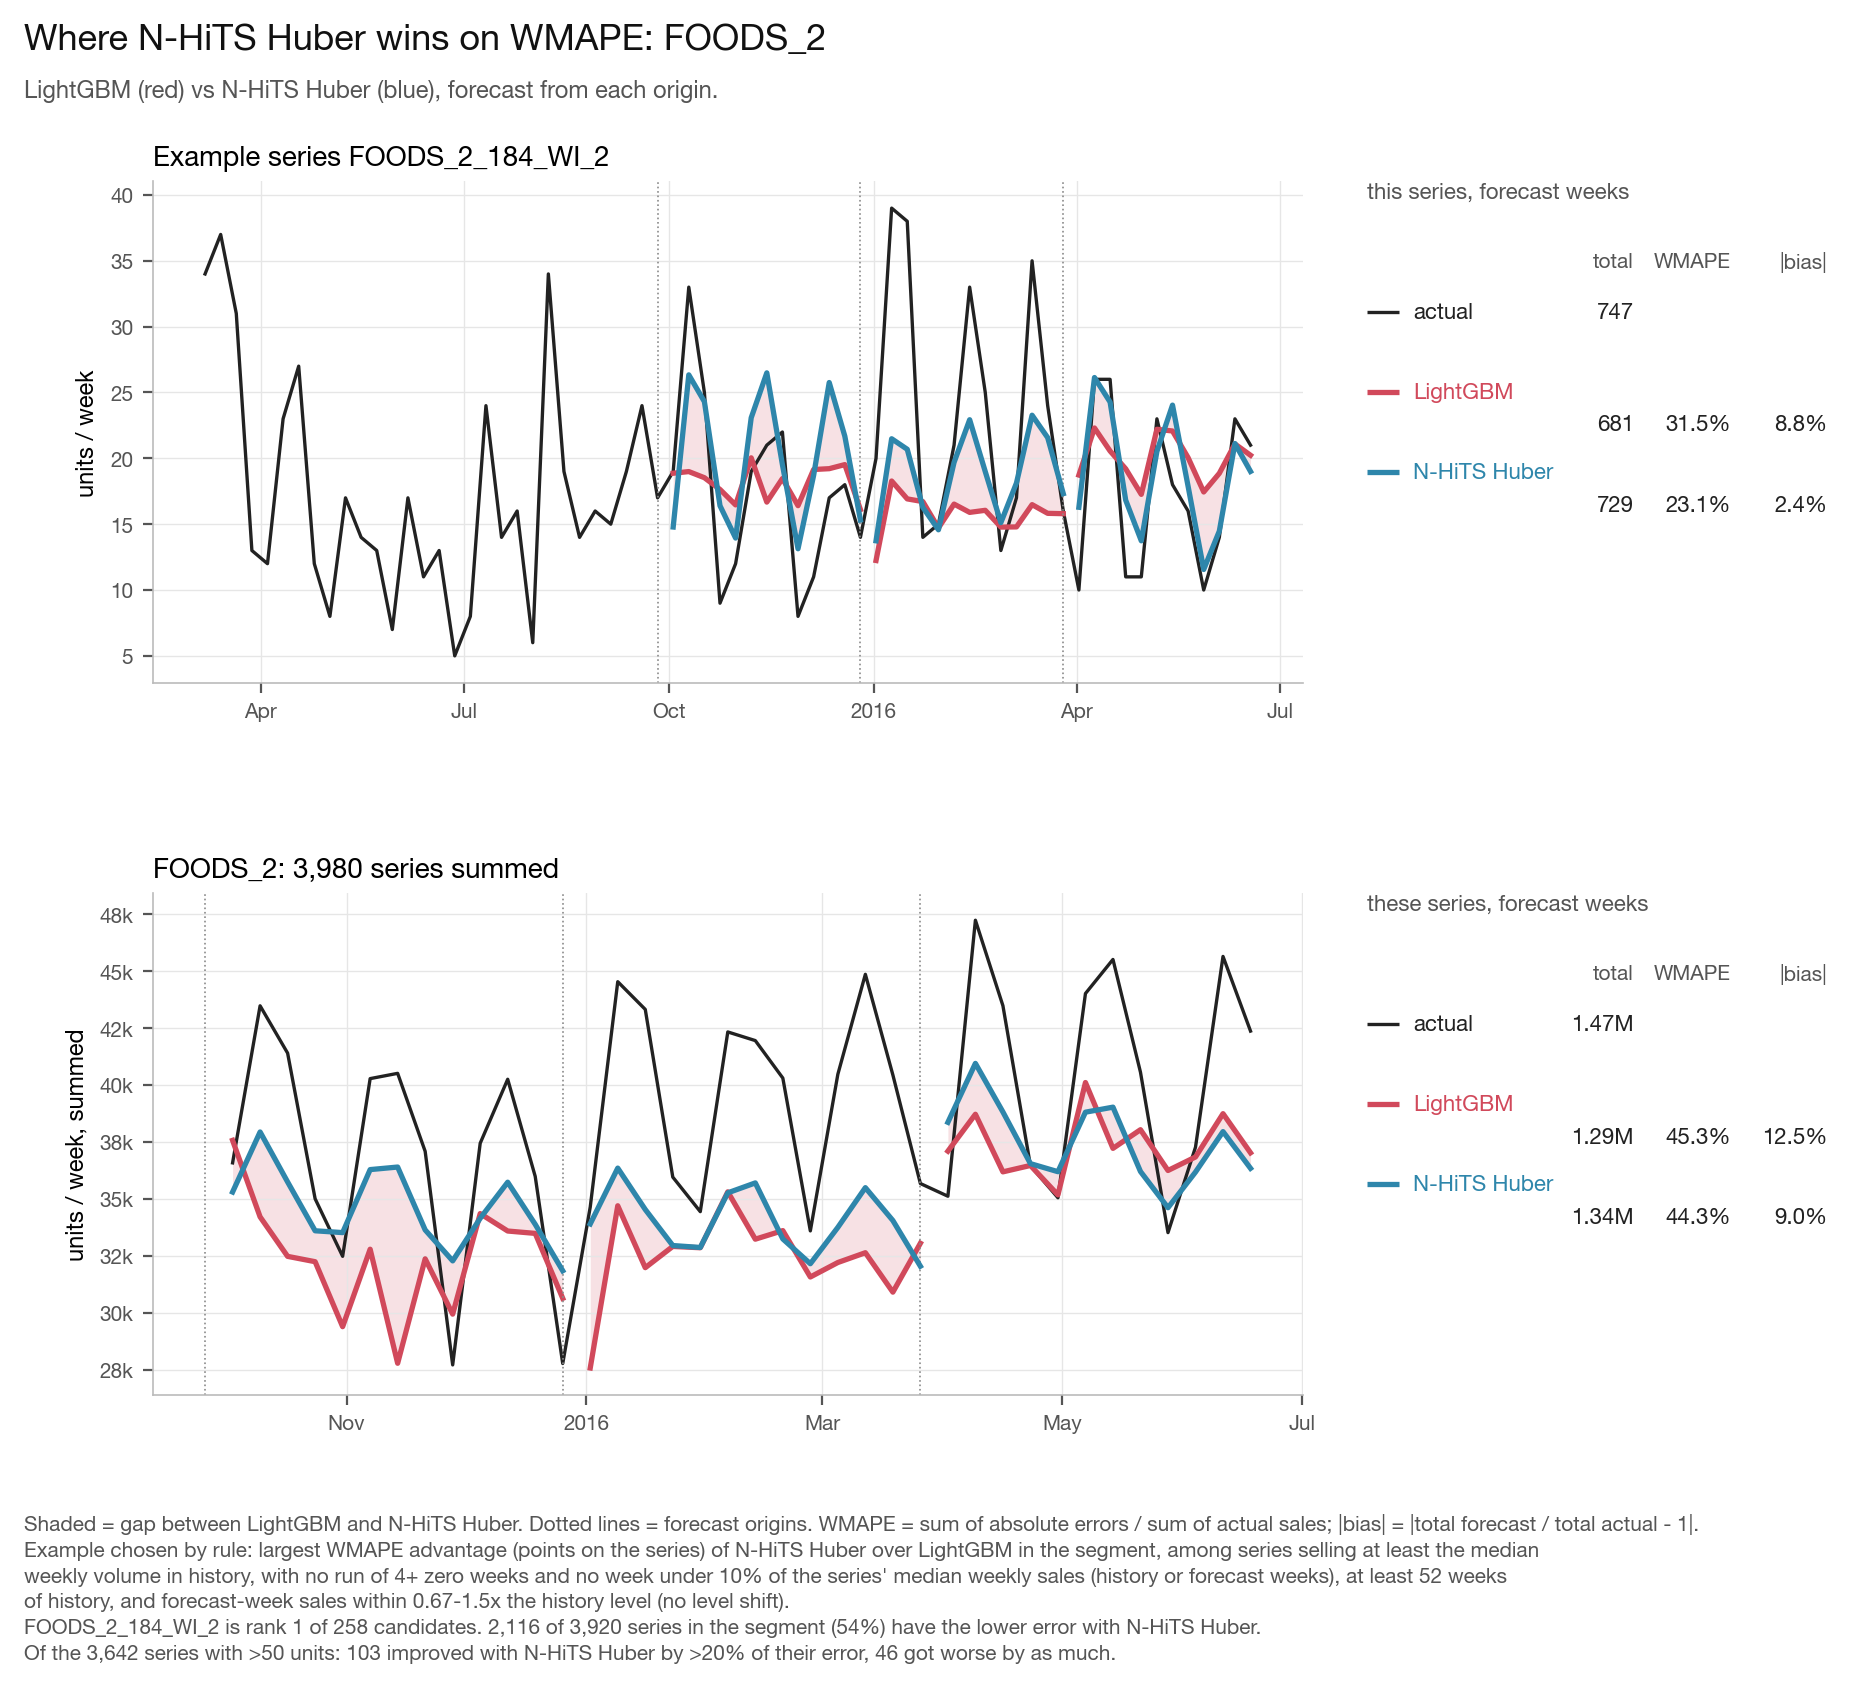

In [32]:
dlead = story.dl_lead(tab)
if dlead is None:
    display(Markdown("No series segment has an N-HiTS Huber WMAPE lead with p < 0.05 within the segment, so there is no "
                     "figure here."))
else:
    dmask = seg[dlead["segment_kind"]] == dlead["segment"]
    pw = examples.pick_right_wins_segment(tl, dmask)
    show(compare.draw(R, "f4_lgbm", "f3_fix", pw, L, f"Where N-HiTS Huber wins on WMAPE: {dlead['segment']}",
                      "story_dl_wins_wmape", population=seg.index[dmask], population_label=dlead["segment"]))

In [33]:
if dlead is not None:
    display(Markdown("\n\n".join([
        f"N-HiTS Huber's largest clear WMAPE lead is in **{story.segment_name(dlead)}**: WMAPE {dlead['wmape_dl']:.2f} vs "
        f"{dlead['wmape_lgbm']:.2f} ({segments.p_text(dlead['p_wmape'])} within the segment).",
        story.group_line(tl, dmask, L, dlead["segment"]), story.example_line(pw, L), story.typical_line(pw, L)])))

N-HiTS Huber's largest clear WMAPE lead is in **FOODS_2 (14% of volume)**: WMAPE 44.32 vs 45.26 (p < 0.001 within the segment).

FOODS_2, counting only the series and weeks both models forecast (so the numbers differ slightly from the segment table): 3,920 series, 14% of volume. LightGBM WMAPE 45.08, |bias| 12.2% (under-forecast); N-HiTS Huber WMAPE 43.91, |bias| 8.3% (under-forecast). Series by series it is mixed: N-HiTS Huber has the lower error on 54% of them. By metric: N-HiTS Huber has the lower WMAPE (-1.17); N-HiTS Huber has the smaller |bias| (-3.9pt) (differences are N-HiTS Huber minus LightGBM).

On FOODS_2_184_WI_2: LightGBM WMAPE 31.5, |bias| 8.8%; N-HiTS Huber WMAPE 23.1, |bias| 2.4%.

The example (FOODS_2_184_WI_2) is the rule's top case (rank 1 of 258 candidates). 2,116 of the 3,920 series in the segment (54%) have the lower error with N-HiTS Huber. Of the 3,642 series selling more than 50 units, 103 got more than 20% better with N-HiTS Huber and 46 got worse by as much; on 1,973 of them the two forecasts differ by more than 10%.

### 5.4 Where LightGBM wins

**Claim.** LightGBM still leads in some places. The code below finds the series segment (by volume, zero weeks or
department) where its WMAPE lead is largest; the numbers below show whether N-HiTS Huber still has the smaller |bias|
there. The example is LightGBM's largest WMAPE advantage in that segment among steady series (the same filters as in 5.2).
N-HiTS Huber is fit once, so its weights get older with each origin; the per-origin numbers below show where LightGBM
leads. This repo has no refit N-HiTS Huber run, so it cannot say whether refitting would close a gap. The detail figure
shows every department and origin.

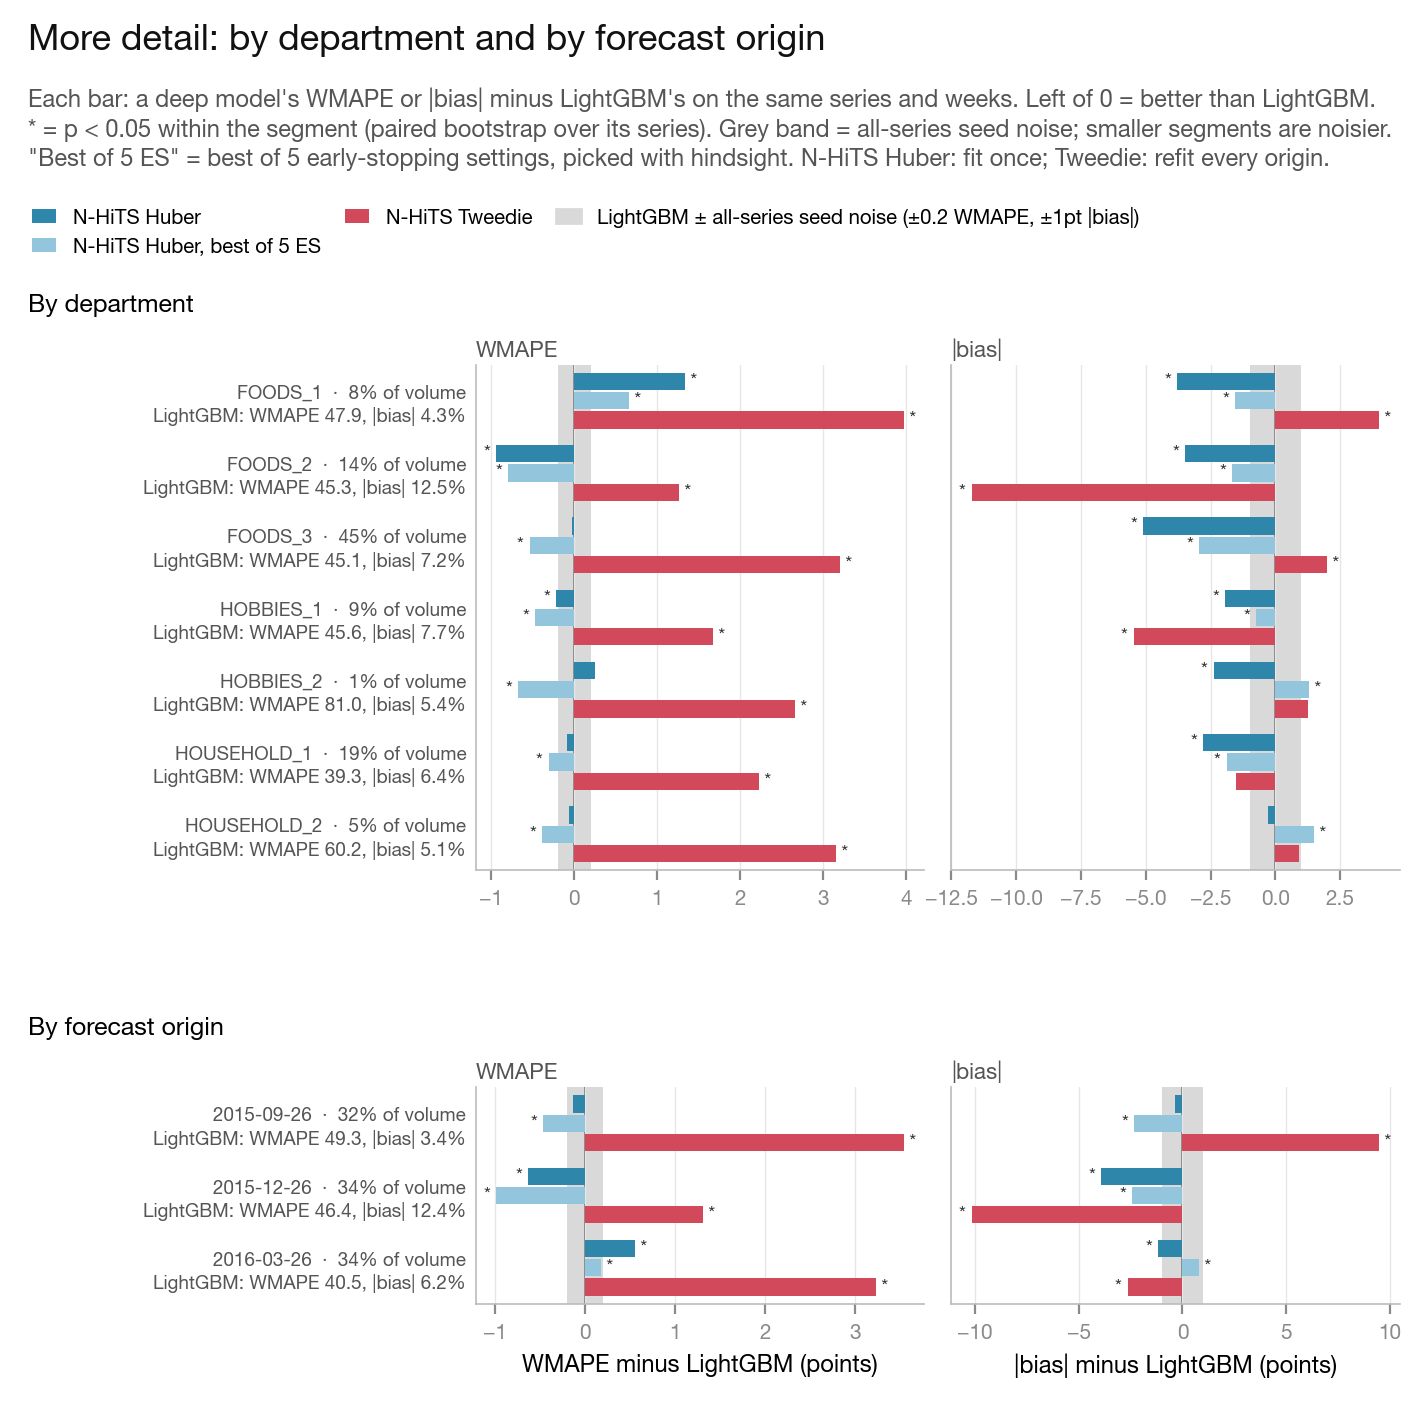

By origin, N-HiTS Huber minus LightGBM: 2015-09-26 (N-HiTS weights 0 weeks old): WMAPE -0.13 (p = 0.311), |bias| -0.4pt; 2015-12-26 (N-HiTS weights 13 weeks old): WMAPE -0.63 (p < 0.001), |bias| -3.9pt; 2016-03-26 (N-HiTS weights 26 weeks old): WMAPE +0.55 (p < 0.001), |bias| -1.2pt. LightGBM has a clear WMAPE lead at: 2016-03-26 (26 weeks).

In [34]:
show(seg_fig.draw(tab, MODELS, kinds=story.DETAIL_KINDS, name="story_segments_detail",
                  title="More detail: by department and by forecast origin"))
og = sg[sg.segment_kind == "origin"].reset_index(drop=True)
cuts = pd.to_datetime(og.segment)
age = {r.segment: int((c - cuts[0]).days / 7) for r, c in zip(og.itertuples(), cuts)}
display(Markdown("By origin, N-HiTS Huber minus LightGBM: " + "; ".join(
    f"{r.segment} (N-HiTS weights {age[r.segment]} weeks old): WMAPE {r.d_wmape:+.2f} ({segments.p_text(r.p_wmape)}), "
    f"|bias| {r.d_absbias:+.1f}pt" for r in og.itertuples()) + ". LightGBM has a clear WMAPE lead at: "
    + (style_join([f"{r.segment} ({age[r.segment]} weeks)" for r in og.itertuples() if r.wmape_read == "LightGBM"]) or "none") + "."))

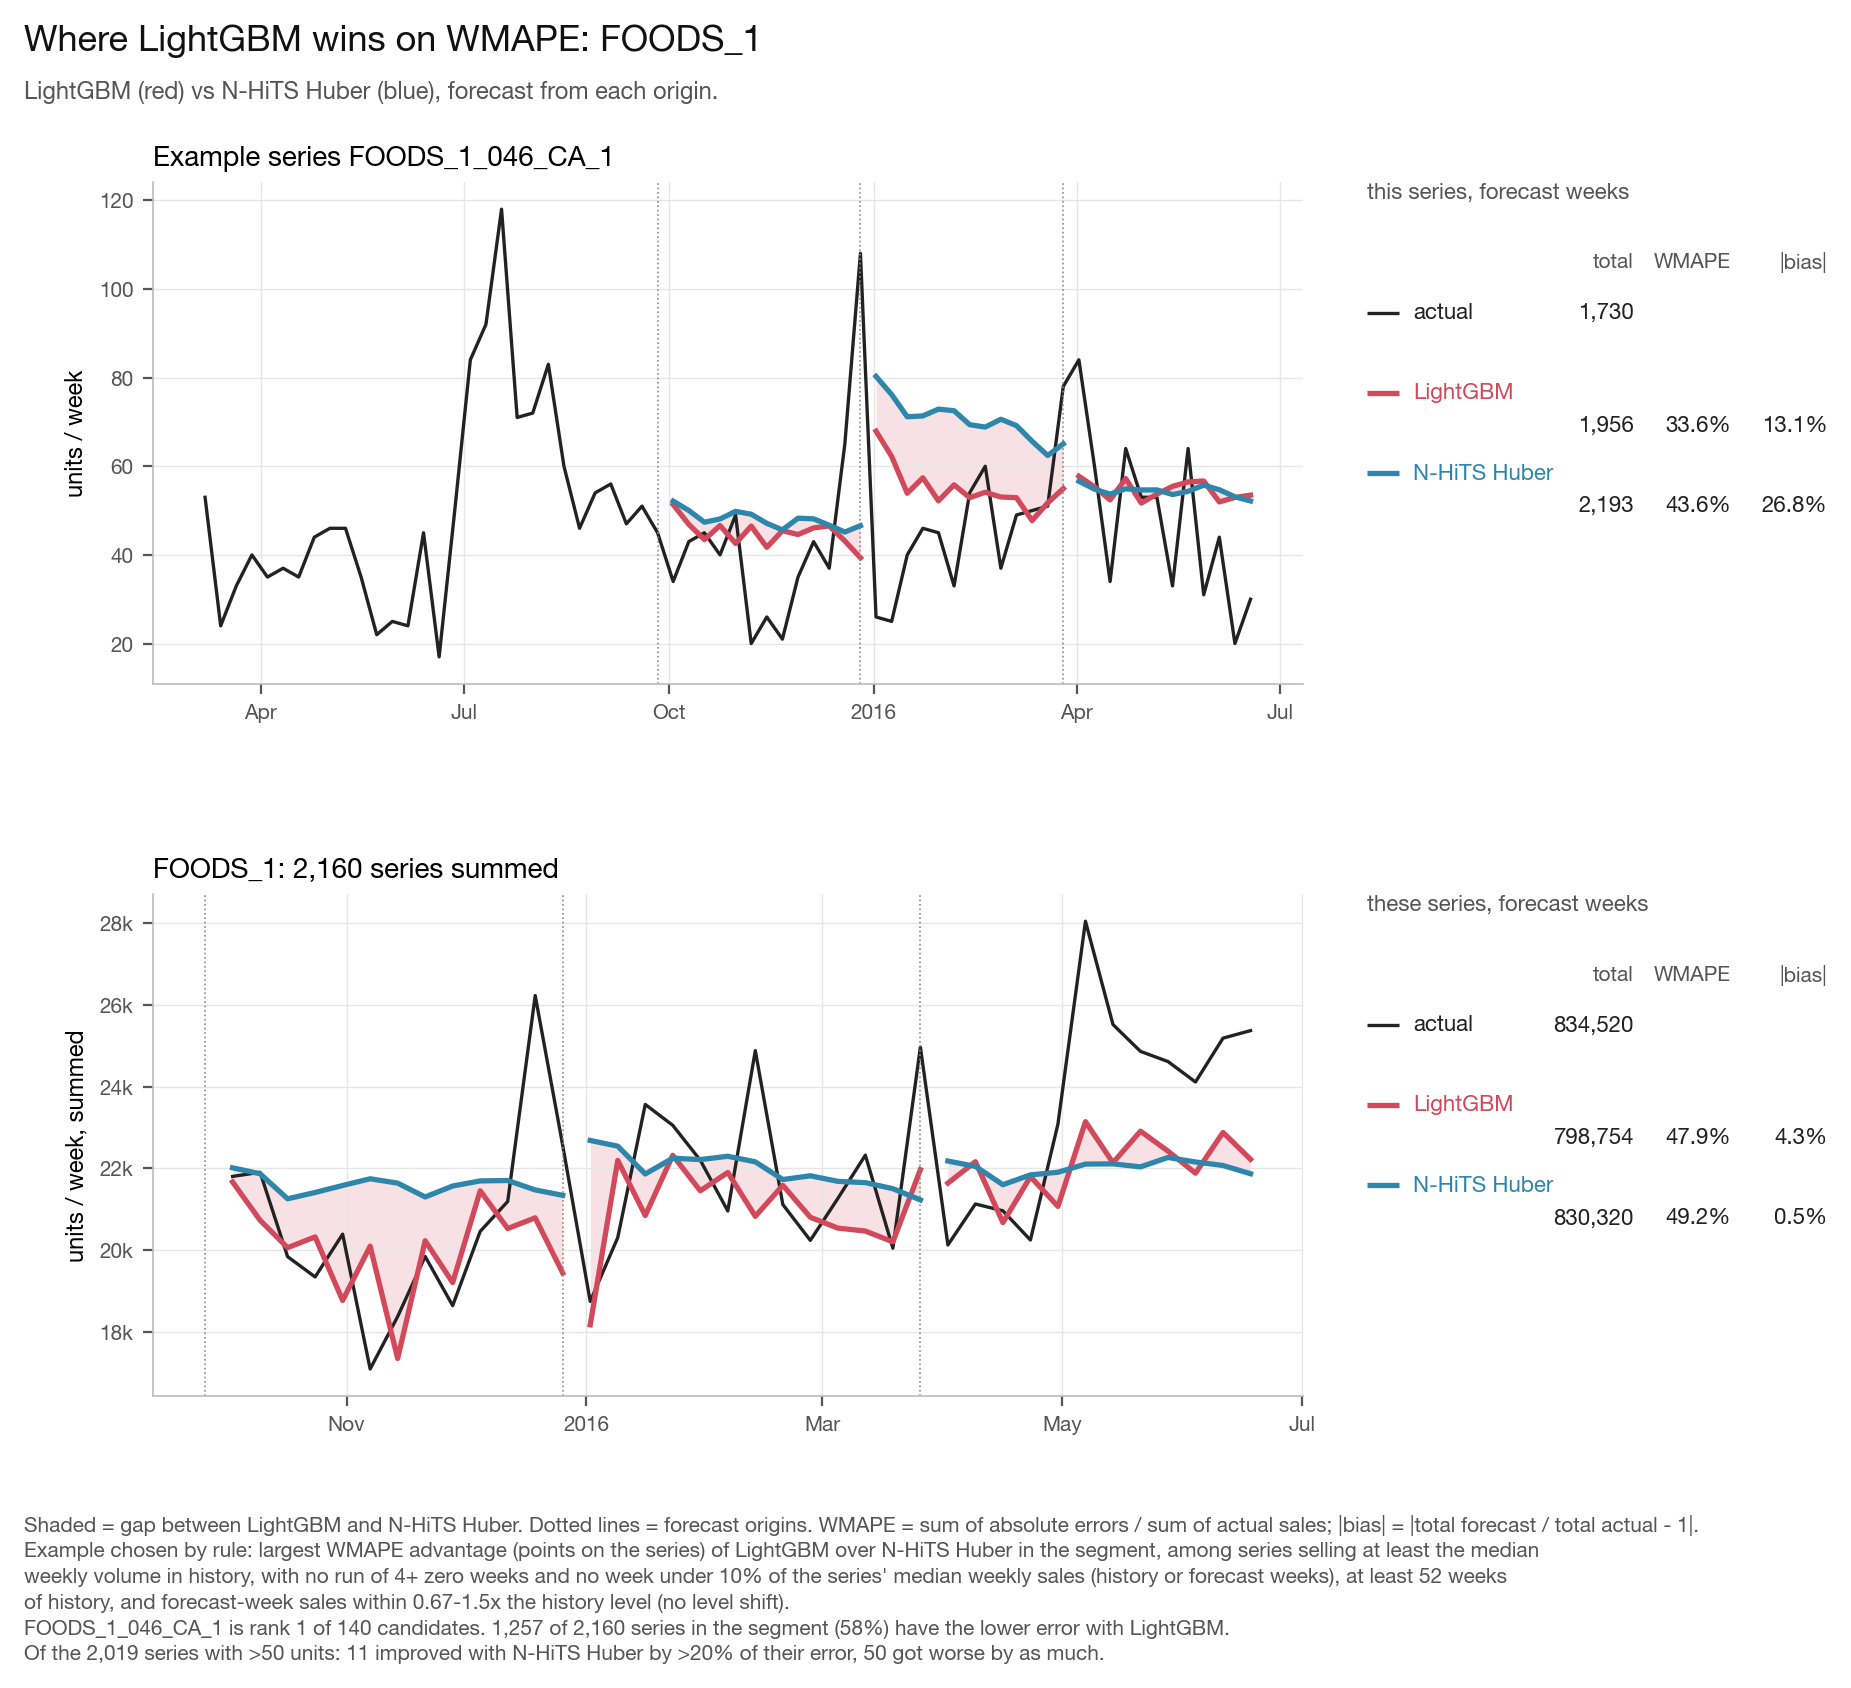

In [35]:
lead = story.lightgbm_lead(tab)
assert lead is not None, "no segment with a clear LightGBM WMAPE lead: rewrite 5.4"
mask = seg[lead["segment_kind"]] == lead["segment"]
p = examples.pick_wrong_wins_segment(tl, mask)  # steady series (no stock-outs) with a full year of history
show(compare.draw(R, "f4_lgbm", "f3_fix", p, L, f"Where LightGBM wins on WMAPE: {lead['segment']}",
                  "story_lightgbm_wins", population=seg.index[mask], population_label=lead["segment"]))

In [36]:
c = story.concentration(tl, mask)
display(Markdown("\n\n".join([
    f"LightGBM's largest clear lead is in **{lead['segment']}** ({lead['segment_kind']}): WMAPE {lead['wmape_lgbm']:.2f} vs "
    f"{lead['wmape_dl']:.2f} ({segments.p_text(lead['p_wmape'])} within the segment), |bias| {lead['absbias_lgbm']:.1f}% vs "
    f"{lead['absbias_dl']:.1f}%.",
    story.group_line(tl, mask, L, lead["segment"]), story.example_line(p, L, favours="wrong"),
    story.typical_line(p, L),
    f"The {c['k']} series with LightGBM's largest advantages carry {c['share']:.0%} of its lead in {lead['segment']}; without "
    f"them LightGBM still leads by {c['lead_without']:.2f} WMAPE (vs {c['lead']:.2f} with them)."])))

LightGBM's largest clear lead is in **FOODS_1** (department): WMAPE 47.87 vs 49.20 (p < 0.001 within the segment), |bias| 4.3% vs 0.5%.

FOODS_1, counting only the series and weeks both models forecast (so the numbers differ slightly from the segment table): 2,160 series, 8% of volume. LightGBM WMAPE 47.87, |bias| 4.3% (under-forecast); N-HiTS Huber WMAPE 49.20, |bias| 0.5% (under-forecast). Series by series it is mixed: N-HiTS Huber has the lower error on 42% of them. The result splits by metric: LightGBM has the lower WMAPE (+1.34); N-HiTS Huber has the smaller |bias| (-3.8pt) (differences are N-HiTS Huber minus LightGBM).

On FOODS_1_046_CA_1: LightGBM WMAPE 33.6, |bias| 13.1%; N-HiTS Huber WMAPE 43.6, |bias| 26.8%.

The example (FOODS_1_046_CA_1) is the rule's top case (rank 1 of 140 candidates). 1,257 of the 2,160 series in the segment (58%) have the lower error with LightGBM. Of the 2,019 series selling more than 50 units, 11 got more than 20% better with N-HiTS Huber and 50 got worse by as much; on 1,005 of them the two forecasts differ by more than 10%. More series got clearly worse than better with N-HiTS Huber on their own error.

The 10 series with LightGBM's largest advantages carry 35% of its lead in FOODS_1; without them LightGBM still leads by 0.88 WMAPE (vs 1.34 with them).

## 6. Where to use deep learning on weekly retail

Every model and setting in this notebook, scored over all series, weeks and origins:

In [37]:
display(story.summary_table(R).set_index("model / setting"))

,arm,fit,WMAPE,bias %,|bias| %
model / setting,,,,,
"N-HiTS Tweedie, clip off",f2_noclip,fit once,49.27,8.1,8.1
"N-HiTS Tweedie, AutoClip (the recipe)",f2_clip,fit once,48.14,6.3,6.3
"N-HiTS Huber, input_size=13",f3_input13,fit once,46.57,-2.3,2.3
"N-HiTS Huber, patience 250 steps, no min-steps guard",f3_patience250,fit once,45.93,-0.5,0.5
"N-HiTS Huber, patience 1,000 steps, no min-steps guard",f3_fix_noguard,fit once,45.27,-3.6,3.6
N-HiTS MAE loss,f3_mae,fit once,45.45,-9.8,9.8
"N-HiTS Huber, MinMax scaler",f3_minmax,fit once,45.12,-0.6,0.6
N-HiTS Huber (pre-set recipe),f3_fix,fit once,45.27,-3.6,3.6
"N-HiTS Huber, best of 5 early-stopping settings (hindsight)",es_p4000,fit once,44.92,-5.4,5.4


In [38]:
gi = gaps.set_index("model")
ln = lambda g: "beats" if g < -data.SEED_NOISE["wape"] else "trails" if g > data.SEED_NOISE["wape"] else "ties"  # noqa: E731
h, b, es = gi.loc["N-HiTS Huber"], gi.loc["LightGBM"], gi.loc["N-HiTS Huber, best of 5 ES"]
fast = story.group_metrics(tl, steady)
display(Markdown("\n".join([
    f"- **Overall:** N-HiTS Huber, fit once, {ln(h.gap)} LightGBM on WMAPE ({h.wape:.2f} vs {b.wape:.2f}, "
    f"{segments.p_text(h.p)}) with {abs(h.abs_bias_gap):.1f}pt less |bias| ({h.abs_bias:.1f}% vs {b.abs_bias:.1f}%).",
    f"- **Fast, steady sellers** ({fast['vol_share']:.0%} of volume): WMAPE {fast['wmape_right']:.2f} vs {fast['wmape_wrong']:.2f}, "
    f"|bias| {abs(fast['bias_right']):.1f}% vs {abs(fast['bias_wrong']):.1f}% (N-HiTS Huber vs LightGBM).",
    f"- **With hindsight** (best of 5 early-stopping settings): WMAPE {es.wape:.2f}, {ln(es.gap)} LightGBM ({es.gap:+.2f}).",
    "- **Stock Tweedie:** " + "; ".join(f"{m} {gi.loc[m, 'gap']:+.2f} WMAPE, bias {gi.loc[m, 'bias']:+.1f}%"
                                        for m in gi.index if "Tweedie" in m) + " against LightGBM."])))

- **Overall:** N-HiTS Huber, fit once, ties LightGBM on WMAPE (45.27 vs 45.35, p = 0.305) with 3.8pt less |bias| (3.6% vs 7.4%).
- **Fast, steady sellers** (51% of volume): WMAPE 35.06 vs 35.03, |bias| 0.4% vs 4.9% (N-HiTS Huber vs LightGBM).
- **With hindsight** (best of 5 early-stopping settings): WMAPE 44.92, beats LightGBM (-0.43).
- **Stock Tweedie:** N-HiTS Tweedie +2.67 WMAPE, bias +6.1%; TCN Tweedie +1.86 WMAPE, bias +4.6% against LightGBM.

Segment by segment, N-HiTS Huber against LightGBM (p < 0.05 within each segment; the ±0.2 bar is all-series seed noise):

In [39]:
display(Markdown("\n".join(f"- {s}" for s in story.where_bullets(tab))))

- N-HiTS Huber beats LightGBM on WMAPE at p < 0.05 within the segment: FOODS_2 (14% of volume), -0.9, origin 2015-12-26 (34% of volume), -0.6, volume Q1 slowest (5% of volume), -0.5, 10–50% zero weeks (31% of volume), -0.3 and HOBBIES_1 (9% of volume), -0.2.
- LightGBM beats N-HiTS Huber on WMAPE at p < 0.05 within the segment: FOODS_1 (8% of volume), +1.3 and origin 2016-03-26 (34% of volume), +0.6.
- N-HiTS Huber beats LightGBM on |bias| at p < 0.05 within the segment: volume Q4 fastest (69% of volume), -5.6pt, FOODS_3 (45% of volume), -5.1pt, <10% zero weeks (62% of volume), -4.6pt, origin 2015-12-26 (34% of volume), -3.9pt, FOODS_1 (8% of volume), -3.8pt, 10–50% zero weeks (31% of volume), -3.5pt, FOODS_2 (14% of volume), -3.5pt, HOUSEHOLD_1 (19% of volume), -2.8pt, HOBBIES_2 (1% of volume), -2.4pt, HOBBIES_1 (9% of volume), -1.9pt, volume Q3 (18% of volume), -1.7pt and origin 2016-03-26 (34% of volume), -1.2pt.
- LightGBM beats N-HiTS Huber on |bias| at p < 0.05 within the segment: volume Q1 slowest (5% of volume), +4.7pt, >50% zero weeks (7% of volume), +1.3pt and volume Q2 (9% of volume), +0.8pt.
- No clear WMAPE difference (p ≥ 0.05) in 10 of 17 segments: volume Q2 (9% of volume), volume Q3 (18% of volume), volume Q4 fastest (69% of volume), <10% zero weeks (62% of volume), >50% zero weeks (7% of volume), FOODS_3 (45% of volume), HOBBIES_2 (1% of volume), HOUSEHOLD_1 (19% of volume), HOUSEHOLD_2 (5% of volume) and origin 2015-09-26 (32% of volume).

In [40]:
ser = sg[sg.segment_kind.isin(story.SERIES_KINDS)]
lg = [story.segment_name(r) for _, r in ser[ser.wmape_read == "LightGBM"].iterrows()]
dl = [story.segment_name(r) for _, r in ser[ser.wmape_read == "deep learning"].iterrows()]
tweedie = [m for m in gi.index if "Tweedie" in m and gi.loc[m, "gap"] > data.SEED_NOISE["wape"]]
display(Markdown(
    f"**In practice.** Start from N-HiTS with Huber loss and the settings from section 3 (AutoClip on, a {r['input_size']}-week "
    f"input window, {r['early_stop_patience_steps'] * r['val_check_steps']:,} steps of early-stopping patience, best weights "
    f"restored). Here it {ln(h.gap)} LightGBM on WMAPE ({h.gap:+.2f}) with {-h.abs_bias_gap:.1f}pt less |bias|; its largest "
    f"clear |bias| advantage is in {story.segment_name(best)}, and it has a clear WMAPE lead in "
    f"{style_join(dl) or 'no series segment'}. LightGBM keeps a clear WMAPE lead in "
    f"{style_join(lg) or 'no series segment'}. Refitting the deep model more often than once every two quarters is worth "
    "testing; it was not tested here. " + (f"Avoid stock Tweedie ({style_join(tweedie)} trail LightGBM on WMAPE). " if tweedie else "")
    + "Judge every change on WMAPE and |bias| together."))

**In practice.** Start from N-HiTS with Huber loss and the settings from section 3 (AutoClip on, a 52-week input window, 1,000 steps of early-stopping patience, best weights restored). Here it ties LightGBM on WMAPE (-0.07) with 3.8pt less |bias|; its largest clear |bias| advantage is in volume Q4 fastest (69% of volume), and it has a clear WMAPE lead in volume Q1 slowest (5% of volume), 10–50% zero weeks (31% of volume), FOODS_2 (14% of volume) and HOBBIES_1 (9% of volume). LightGBM keeps a clear WMAPE lead in FOODS_1 (8% of volume). Refitting the deep model more often than once every two quarters is worth testing; it was not tested here. Avoid stock Tweedie (N-HiTS Tweedie and TCN Tweedie trail LightGBM on WMAPE). Judge every change on WMAPE and |bias| together.

### The four claims

The verdicts below are computed as described in sections 3 to 5.

In [41]:
display(Markdown("\n\n".join([f"**1. A handful of settings decide whether deep learning works.** {cl['handful']}",
                                f"**2. Wrong settings mostly make the model underfit.** {cl['underfit']}",
                                f"**3. Gradient clipping is non-negotiable for Tweedie.** {stress.headline(O)}.\n\n"
                                + stress.conclusion(V["clipping"]["label"], O) + (f"\n\n{spike_claim}" if spike_claim else ""),
                                f"**4. Deep learning can match gradient-boosted trees.** {story.claim4(gaps)}"])))

**1. A handful of settings decide whether deep learning works.** 4 of 5 cards gave the wrong value a verdict of underfit or biased: Gradient clipping, Input window, Early stopping and Loss function. Largest WMAPE gap among them: +1.30 (Input window, 2.9% of the 'with' run's WMAPE). Verdict on the claim, read as 'for most of the tested settings, the wrong value measurably hurts': holds.

**2. Wrong settings mostly make the model underfit.** 3 of 5 cards gave the wrong value a verdict of underfit: Gradient clipping, Input window and Early stopping. Verdict on the claim, read as 'more than half of the cards are underfit': holds.

**3. Gradient clipping is non-negotiable for Tweedie.** Stress test (3 setups): clipping helped in 2 and no difference in 1.

- At the recipe's settings, the card's verdict on clip off: underfit and biased.
- Learning rate 10× (1e-2): no measurable difference.
- Learning rate 30× (3e-2): neither diverged; the verdict on clip off was underfit and biased.
- Short-history windows let in: neither diverged; the verdict on clip off was underfit.
- Verdict on the claim: **holds** (recipe card: underfit and biased; in favour of clipping: clip off scored worse under the 30× learning rate and clip off scored worse with the short-history filter off).

The larger spikes were in the AutoClip runs (Learning rate 10× (1e-2) and Learning rate 30× (3e-2)), not the unclipped ones. So the stress test does not show clipping preventing instability; clipping's case here rests on the recipe verdict and on where each run ended (WMAPE), not on calmer training.

**4. Deep learning can match gradient-boosted trees.** Claim 4 ('deep learning can match gradient-boosted trees'), judged on N-HiTS Huber (`f3_fix`, the pre-set recipe, fit once) vs LightGBM (refit at every origin): WMAPE 45.27 vs 45.35 (gap -0.07, p = 0.305; seed noise ±0.2), |bias| 3.6% vs 7.4% (p < 0.001). Verdict: holds.

### Caveats

- **One seed** for every run. The noise bar is approximate (section 1).
- **Rules set after seeing results:** the noise floor in the verdict rule and the stress test's divergence rule.
- **Fit once vs refit:** the setting runs and N-HiTS Huber are fit once at the first origin. LightGBM and the Tweedie
  comparison models are refit at every origin.
- **Series with no sales before an origin** get no neural forecast and are scored as zero (count below).
- **Devices:** reruns on the same machine and device were bit-identical. Across devices, expect small differences.

In [42]:
u = report.unforecast(R)
display(Markdown(f"Series with no sales before an origin: {u['per_min']:,} to {u['per_max']:,} per origin, "
                 f"{u['units'] / u['total']:.2%} of scored volume, the same for every neural run."))
architectures.write_table(R)  # the refit-every-origin table in FINDINGS.md (results/f4_table.csv)
report.check_derived_fresh(R)
display(Markdown(f"Wrote `{os.path.relpath(report.write())}`: every number behind this notebook."))

Series with no sales before an origin: 58 to 82 per origin, 0.13% of scored volume, the same for every neural run.

Wrote `../FINDINGS.md`: every number behind this notebook.